# Telco Customer Churn — Exploratory Data Analysis

This notebook performs **exploratory data analysis (EDA)** on the Telco Customer Churn dataset. The goal is to understand the data, assess its quality, and identify patterns associated with customer churn before building machine-learning models.

**Business question:** Which customer characteristics are associated with leaving or staying on the platform?

> This notebook focuses on EDA only. It does not yet split the data, encode features, train models, or tune hyperparameters.

## Learning objectives

By the end of this notebook, we will:

1. Load and inspect the dataset.
2. Check data quality and handle the `TotalCharges` field for analysis.
3. Examine the target class and numerical variables.
4. Explore categorical variables and churn-rate differences.
5. Identify relationships between customer attributes and churn.
6. Summarize the most important EDA findings and plan the modeling stage.

In [1]:
# Install the required packages if needed:
# python -m pip install pandas numpy matplotlib seaborn

import warnings
warnings.filterwarnings('ignore', category=FutureWarning)

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid', context='notebook')
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)
pd.set_option('display.float_format', lambda value: f'{value:,.2f}')

print(f'pandas {pd.__version__} | numpy {np.__version__} | seaborn {sns.__version__}')

pandas 3.0.5 | numpy 2.5.2 | seaborn 0.13.2


## 1. Load the dataset

The code below searches the notebook's current directory and its parent for the CSV file, so it remains easy to run from the project folder.

In [2]:
DATA_FILENAME = 'WA_Fn-UseC_-Telco-Customer-Churn.csv'
search_locations = [Path.cwd(), Path.cwd().parent]
data_path = next(
    (location / DATA_FILENAME for location in search_locations if (location / DATA_FILENAME).exists()),
    None,
)

if data_path is None:
    raise FileNotFoundError(
        f'Could not find {DATA_FILENAME} in {[str(path) for path in search_locations]}'
    )

df = pd.read_csv(data_path)
print(f'Loaded: {data_path.resolve()}')
print(f'Shape: {df.shape[0]:,} rows x {df.shape[1]} columns')

Loaded: E:\Data Prep\Deep Learing with Sheryians\1st project\WA_Fn-UseC_-Telco-Customer-Churn.csv
Shape: 7,043 rows x 21 columns


## 2. Dataset structure and first records

A quick structural overview helps us understand what each column represents and whether the columns were imported with suitable data types.

In [3]:
print('Columns:')
for index, column in enumerate(df.columns, start=1):
    print(f'{index:>2}. {column}')

display(df.head(8))

Columns:
 1. customerID
 2. gender
 3. SeniorCitizen
 4. Partner
 5. Dependents
 6. tenure
 7. PhoneService
 8. MultipleLines
 9. InternetService
10. OnlineSecurity
11. OnlineBackup
12. DeviceProtection
13. TechSupport
14. StreamingTV
15. StreamingMovies
16. Contract
17. PaperlessBilling
18. PaymentMethod
19. MonthlyCharges
20. TotalCharges
21. Churn


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
5,9305-CDSKC,Female,0,No,No,8,Yes,Yes,Fiber optic,No,No,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.5,Yes
6,1452-KIOVK,Male,0,No,Yes,22,Yes,Yes,Fiber optic,No,Yes,No,No,Yes,No,Month-to-month,Yes,Credit card (automatic),89.10,1949.4,No
7,6713-OKOMC,Female,0,No,No,10,No,No phone service,DSL,Yes,No,No,No,No,No,Month-to-month,No,Mailed check,29.75,301.9,No


In [4]:
dtype_table = pd.DataFrame({
    'Data type': df.dtypes.astype(str),
    'Non-null values': df.notna().sum(),
    'Unique values': df.nunique(dropna=True),
}).sort_values('Data type')

display(dtype_table)

,Data type,Non-null values,Unique values
MonthlyCharges,float64,7043,1585
SeniorCitizen,int64,7043,2
tenure,int64,7043,73
customerID,str,7043,7043
PaymentMethod,str,7043,4
PaperlessBilling,str,7043,2
Contract,str,7043,3
StreamingMovies,str,7043,3
StreamingTV,str,7043,3
TechSupport,str,7043,3


## 3. Data-quality checks

We check for missing values, blank strings, duplicate records, and unique customer identifiers before interpreting the data.

In [5]:
object_columns = df.select_dtypes(include=['object', 'string']).columns
blank_counts = pd.Series(
    {column: df[column].astype('string').str.strip().eq('').sum() for column in object_columns},
    name='Blank strings',
)

quality_table = pd.DataFrame({
    'Missing values': df.isna().sum(),
    'Blank strings': blank_counts,
})

print(f'Duplicate rows: {df.duplicated().sum():,}')
print(f"Unique customer IDs: {df["customerID"].nunique():,} / {len(df):,}")
print(f"Fully duplicated customer IDs: {df["customerID"].duplicated().sum():,}")
display(quality_table[(quality_table != 0).any(axis=1)])

if df.duplicated().sum() == 0 and df['customerID'].nunique() == len(df):
    print('Conclusion: there are no duplicate records and every row represents a unique customer.')

Duplicate rows: 0
Unique customer IDs: 7,043 / 7,043
Fully duplicated customer IDs: 0


,Missing values,Blank strings
MonthlyCharges,0,NaN
SeniorCitizen,0,NaN
TotalCharges,0,11.00
tenure,0,NaN


Conclusion: there are no duplicate records and every row represents a unique customer.


### Handling `TotalCharges` for analysis

`TotalCharges` is imported as text because some rows contain blank values. Converting it to numeric with `errors='coerce'` turns those blanks into missing values. We preserve the original text column and create `TotalCharges_num` solely for numerical EDA.

In [6]:
df['TotalCharges_num'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
df['ChurnFlag'] = df['Churn'].eq('Yes').astype(int)

conversion_table = pd.DataFrame({
    'TotalCharges': [
        df['TotalCharges'].dtype,
        df['TotalCharges_num'].dtype,
        df['TotalCharges_num'].isna().sum(),
    ],
    'Description': [
        'Original text column',
        'Numeric analysis column',
        'Blank values converted to missing',
    ],
}, index=['Dtype', 'Analysis dtype', 'Missing after conversion'])

display(conversion_table)
display(df.loc[df['TotalCharges_num'].isna(), ['customerID', 'tenure', 'MonthlyCharges', 'TotalCharges', 'Churn']].head(12))

,TotalCharges,Description
Dtype,str,Original text column
Analysis dtype,float64,Numeric analysis column
Missing after conversion,11,Blank values converted to missing


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


## 4. Target-variable analysis

The target is `Churn`, where `Yes` means the customer left and `No` means the customer stayed. Understanding the target distribution is essential because it determines whether later models face a balanced or imbalanced classification problem.

,Customers,Percentage
Churn,,
No,5174,73.46
Yes,1869,26.54


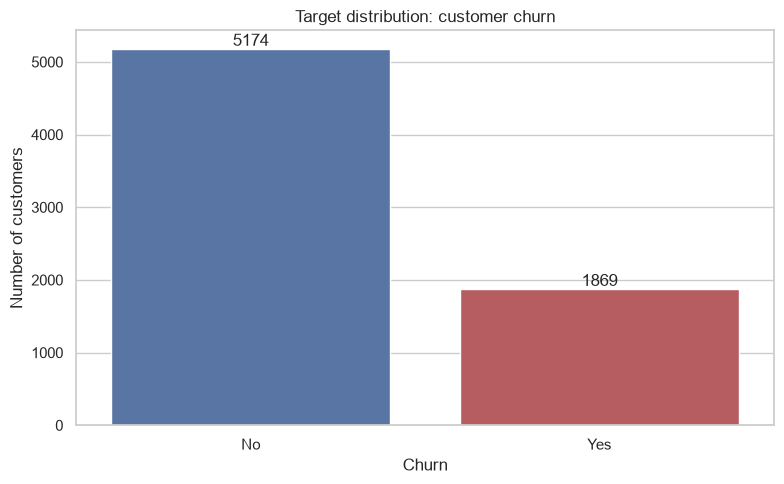

In [7]:
target_summary = df['Churn'].value_counts().rename_axis('Churn').to_frame(name='Customers')
target_summary['Percentage'] = target_summary['Customers'] / len(df) * 100
display(target_summary.round(2))

fig, ax = plt.subplots(figsize=(8, 5))
sns.countplot(data=df, x='Churn', order=['No', 'Yes'], palette={'No': '#4C72B0', 'Yes': '#C44E52'}, ax=ax)
ax.set_title('Target distribution: customer churn')
ax.set_xlabel('Churn')
ax.set_ylabel('Number of customers')
for container in ax.containers:
    ax.bar_label(container, fmt='%,d'.replace(',', ''))
plt.tight_layout()
plt.show()

The dataset is moderately imbalanced: about **26.5%** of customers churn and **73.5%** remain. This means an accuracy-only model could look successful while performing poorly on churned customers. Later modeling should therefore also track precision, recall, F1, ROC AUC, and the confusion matrix, and the train/test split should be stratified.

## 5. Univariate analysis of numerical variables

The main numerical variables are customer tenure, monthly charges, and total charges.

In [8]:
numeric_columns = ['tenure', 'MonthlyCharges', 'TotalCharges_num']
numeric_summary = df[numeric_columns].describe().T
numeric_summary['missing'] = df[numeric_columns].isna().sum()
display(numeric_summary.round(2))

,count,mean,std,min,25%,50%,75%,max,missing
tenure,"7,043.00",32.37,24.56,0.00,9.00,29.00,55.00,72.00,0
MonthlyCharges,"7,043.00",64.76,30.09,18.25,35.50,70.35,89.85,118.75,0
TotalCharges_num,"7,032.00","2,283.30","2,266.77",18.80,401.45,"1,397.48","3,794.74","8,684.80",11


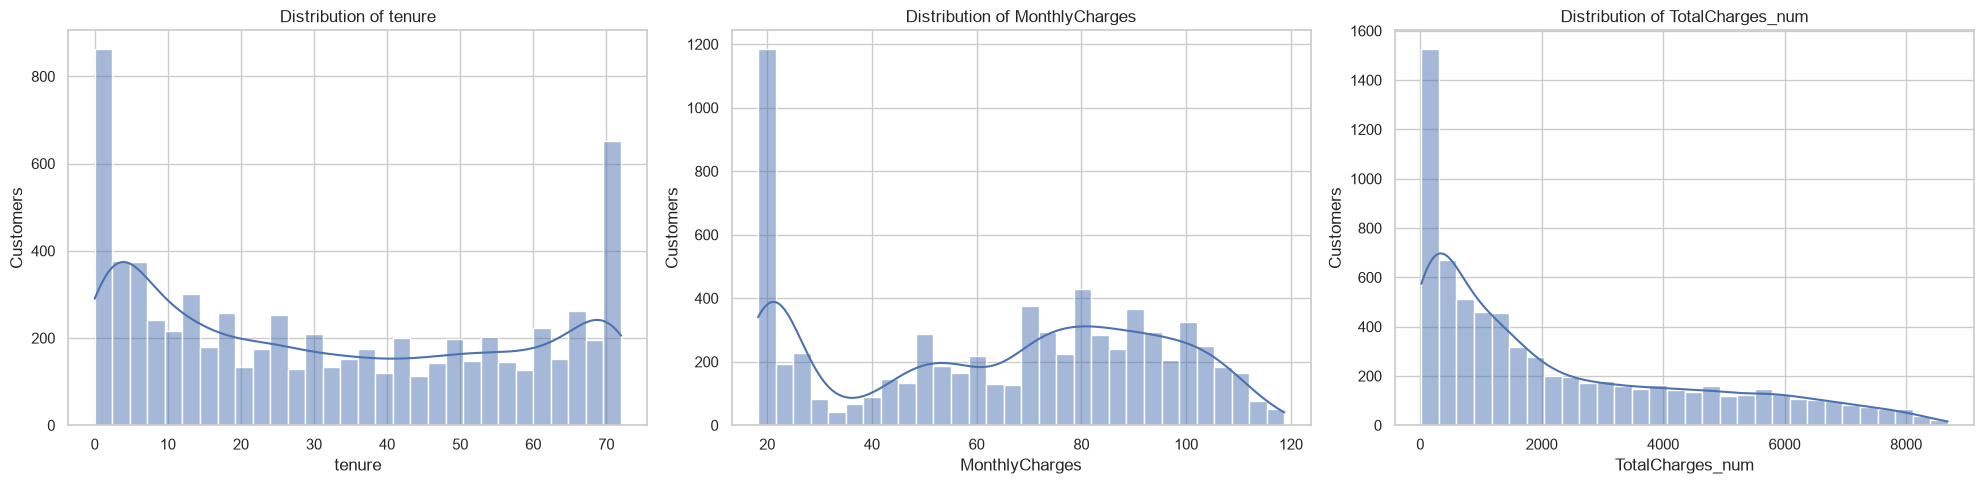

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5))
for ax, column in zip(axes, numeric_columns):
    sns.histplot(data=df, x=column, bins=30, kde=True, color='#4C72B0', ax=ax)
    ax.set_title(f'Distribution of {column}')
    ax.set_xlabel(column)
    ax.set_ylabel('Customers')
plt.tight_layout()
plt.show()

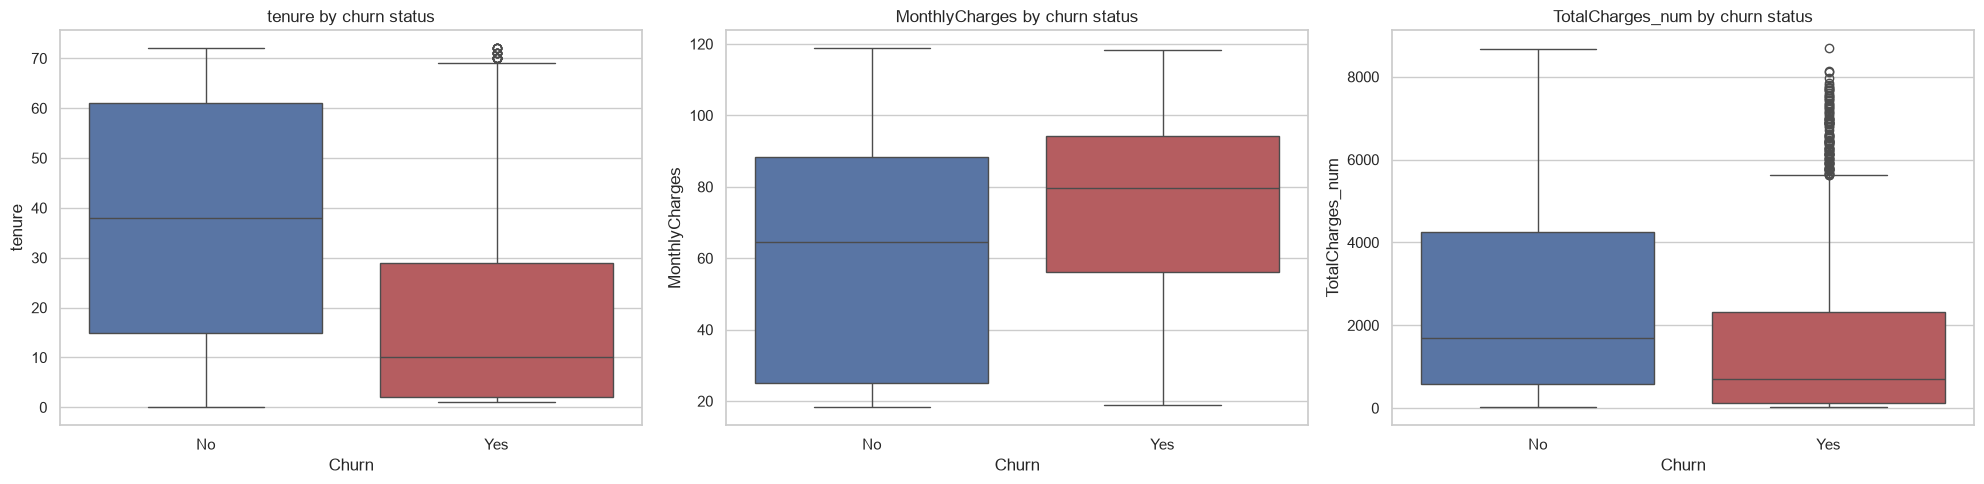

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5))
for ax, column in zip(axes, numeric_columns):
    sns.boxplot(
        data=df,
        x='Churn',
        y=column,
        hue='Churn',
        order=['No', 'Yes'],
        palette={'No': '#4C72B0', 'Yes': '#C44E52'},
        legend=False,
        ax=ax,
    )
    ax.set_title(f'{column} by churn status')
    ax.set_xlabel('Churn')
    ax.set_ylabel(column)
plt.tight_layout()
plt.show()

## 6. Univariate analysis of categorical variables

Most customer attributes are categorical. First, we profile the number of unique values and the most common category for each categorical field.

In [11]:
categorical_columns = [
    'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService',
    'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup',
    'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies',
    'Contract', 'PaperlessBilling', 'PaymentMethod',
]

category_profile = []
for column in categorical_columns:
    counts = df[column].value_counts(dropna=False)
    category_profile.append({
        'Feature': column,
        'Unique values': df[column].nunique(dropna=False),
        'Most common value': counts.index[0],
        'Most common %': counts.iloc[0] / len(df) * 100,
    })

display(pd.DataFrame(category_profile).set_index('Feature').round(2))

,Unique values,Most common value,Most common %
Feature,,,
gender,2,Male,50.48
SeniorCitizen,2,0,83.79
Partner,2,No,51.70
Dependents,2,No,70.04
PhoneService,2,Yes,90.32
MultipleLines,3,No,48.13
InternetService,3,Fiber optic,43.96
OnlineSecurity,3,No,49.67
OnlineBackup,3,No,43.84


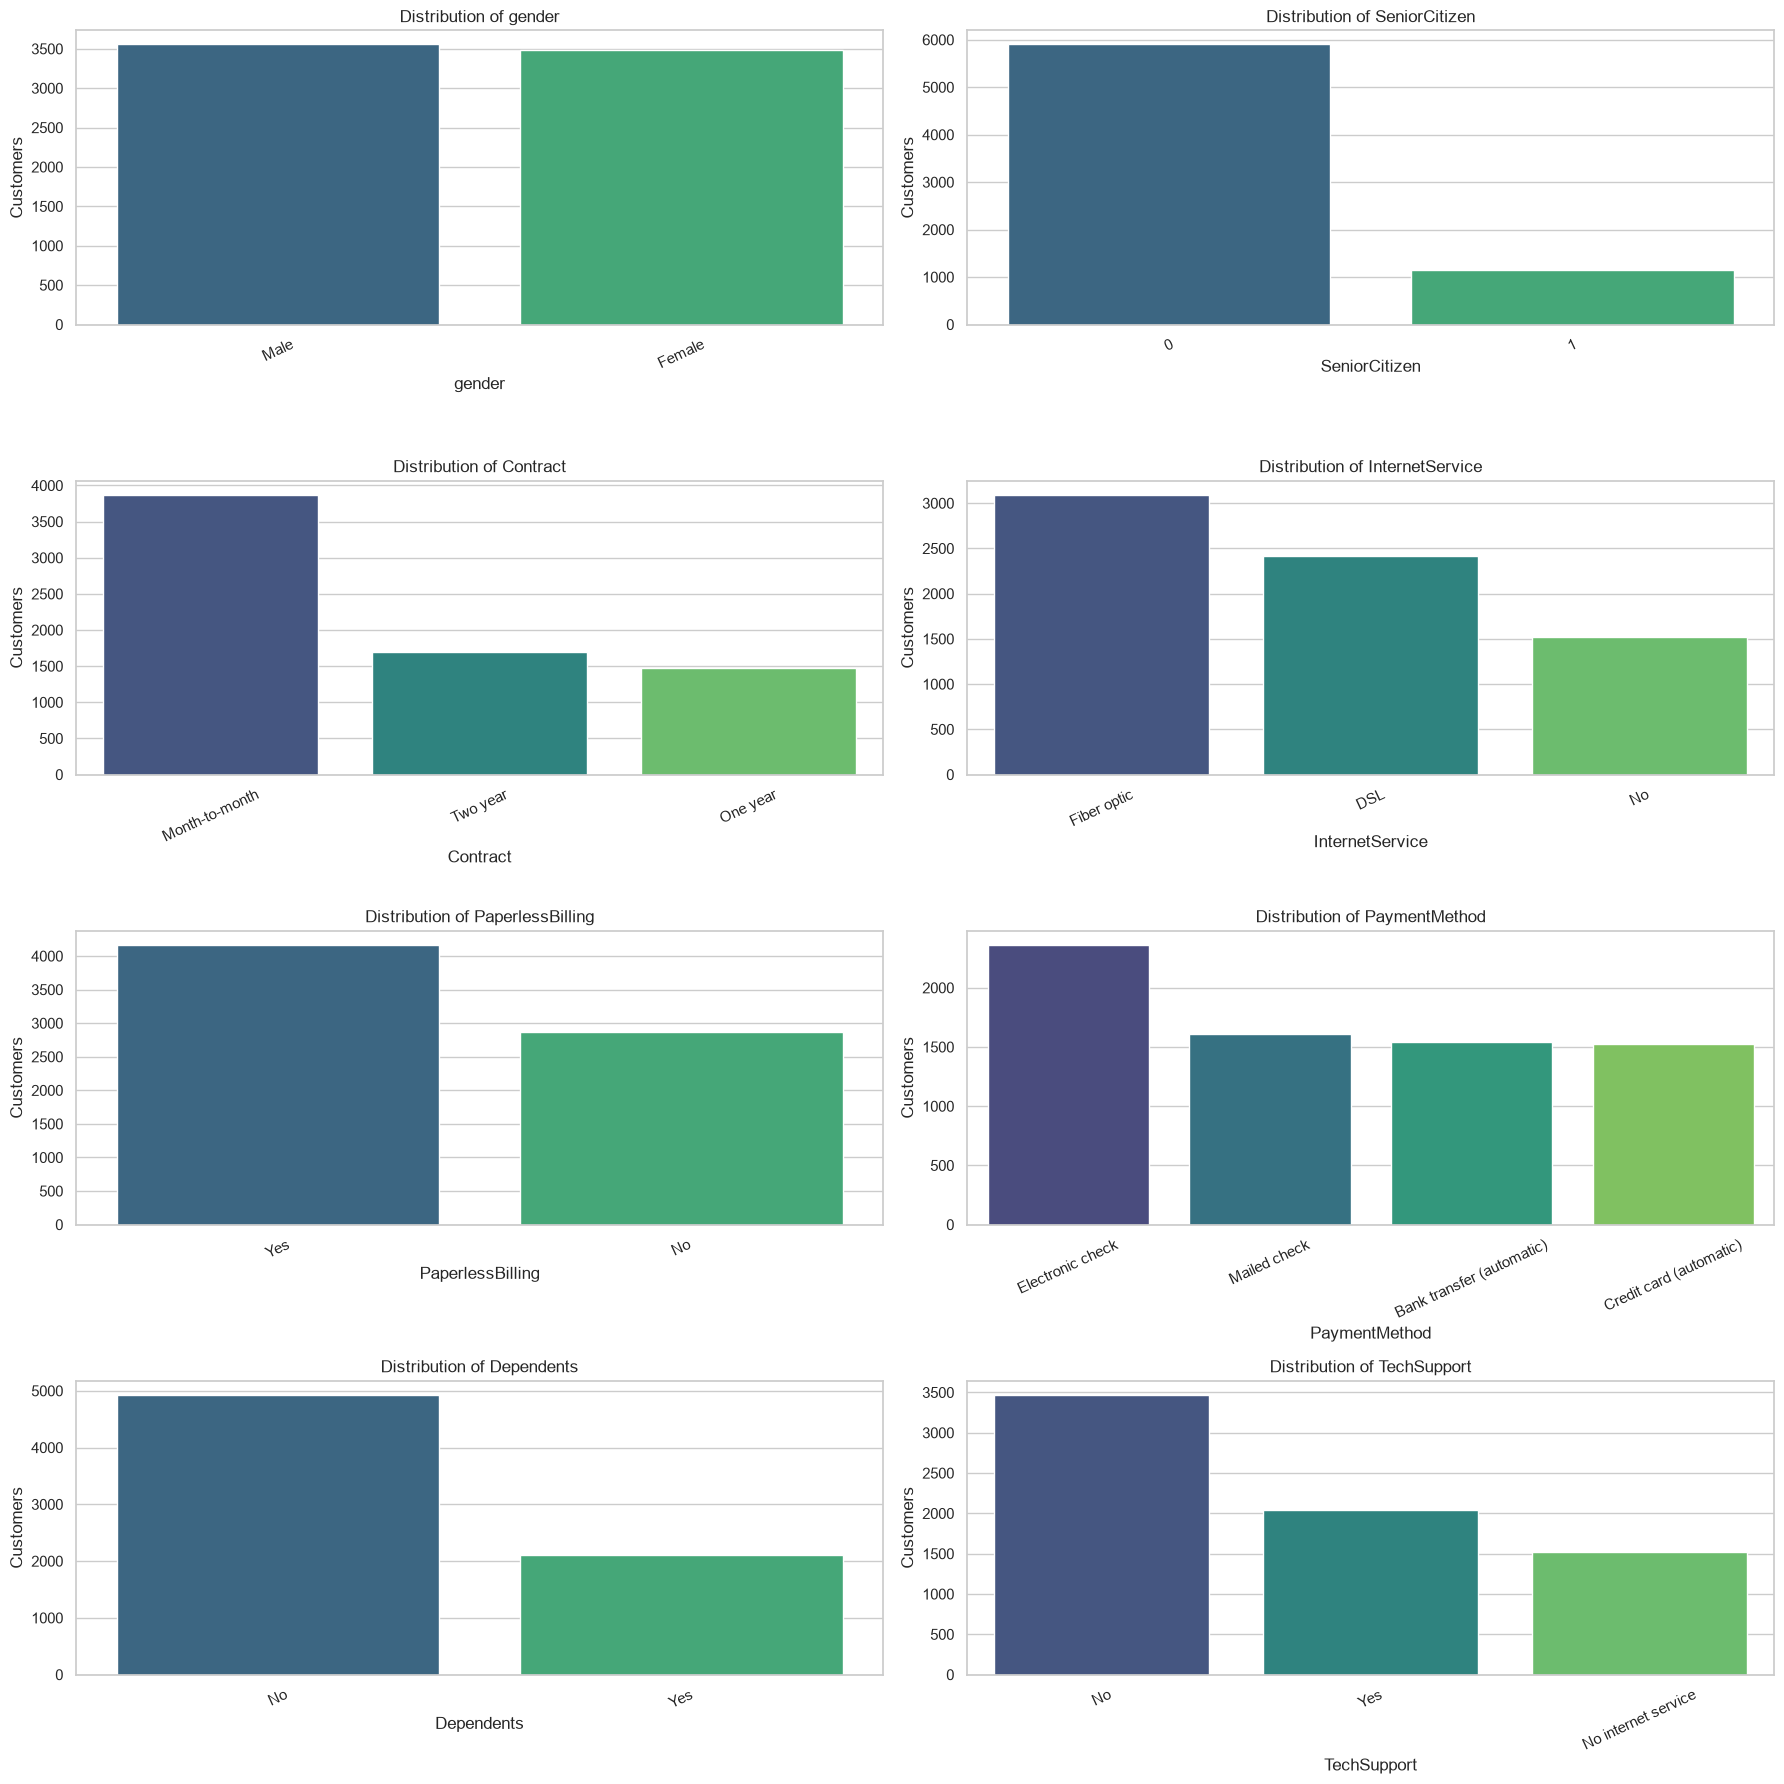

In [12]:
selected_categoricals = [
    'gender', 'SeniorCitizen', 'Contract', 'InternetService',
    'PaperlessBilling', 'PaymentMethod', 'Dependents', 'TechSupport',
]

fig, axes = plt.subplots(4, 2, figsize=(18, 18))
for ax, column in zip(axes.flatten(), selected_categoricals):
    order = df[column].value_counts().index
    sns.countplot(data=df, x=column, order=order, palette='viridis', ax=ax)
    ax.set_title(f'Distribution of {column}')
    ax.set_xlabel(column)
    ax.set_ylabel('Customers')
    ax.tick_params(axis='x', rotation=25)
plt.tight_layout()
plt.show()

## 7. Churn-rate analysis by category

Counts show how common each category is, but churn rates reveal which categories are associated with a higher or lower likelihood of leaving. We calculate both measures below.

In [13]:
def churn_rate_by(column):
    summary = df.groupby(column, dropna=False, observed=True).agg(
        Customers=('ChurnFlag', 'size'),
        Churned=('ChurnFlag', 'sum'),
    )
    summary['Churn Rate (%)'] = summary['Churned'] / summary['Customers'] * 100
    return summary.sort_values('Churn Rate (%)', ascending=False)

for column in ['Contract', 'InternetService', 'PaymentMethod', 'PaperlessBilling', 'TechSupport', 'OnlineSecurity']:
    print(f'\n{column}')
    display(churn_rate_by(column).round(2))


Contract


,Customers,Churned,Churn Rate (%)
Contract,,,
Month-to-month,3875,1655,42.71
One year,1473,166,11.27
Two year,1695,48,2.83



InternetService


,Customers,Churned,Churn Rate (%)
InternetService,,,
Fiber optic,3096,1297,41.89
DSL,2421,459,18.96
No,1526,113,7.40



PaymentMethod


,Customers,Churned,Churn Rate (%)
PaymentMethod,,,
Electronic check,2365,1071,45.29
Mailed check,1612,308,19.11
Bank transfer (automatic),1544,258,16.71
Credit card (automatic),1522,232,15.24


... (2 outputs left out)


TechSupport


,Customers,Churned,Churn Rate (%)
TechSupport,,,
No,3473,1446,41.64
Yes,2044,310,15.17
No internet service,1526,113,7.40



OnlineSecurity


,Customers,Churned,Churn Rate (%)
OnlineSecurity,,,
No,3498,1461,41.77
Yes,2019,295,14.61
No internet service,1526,113,7.40


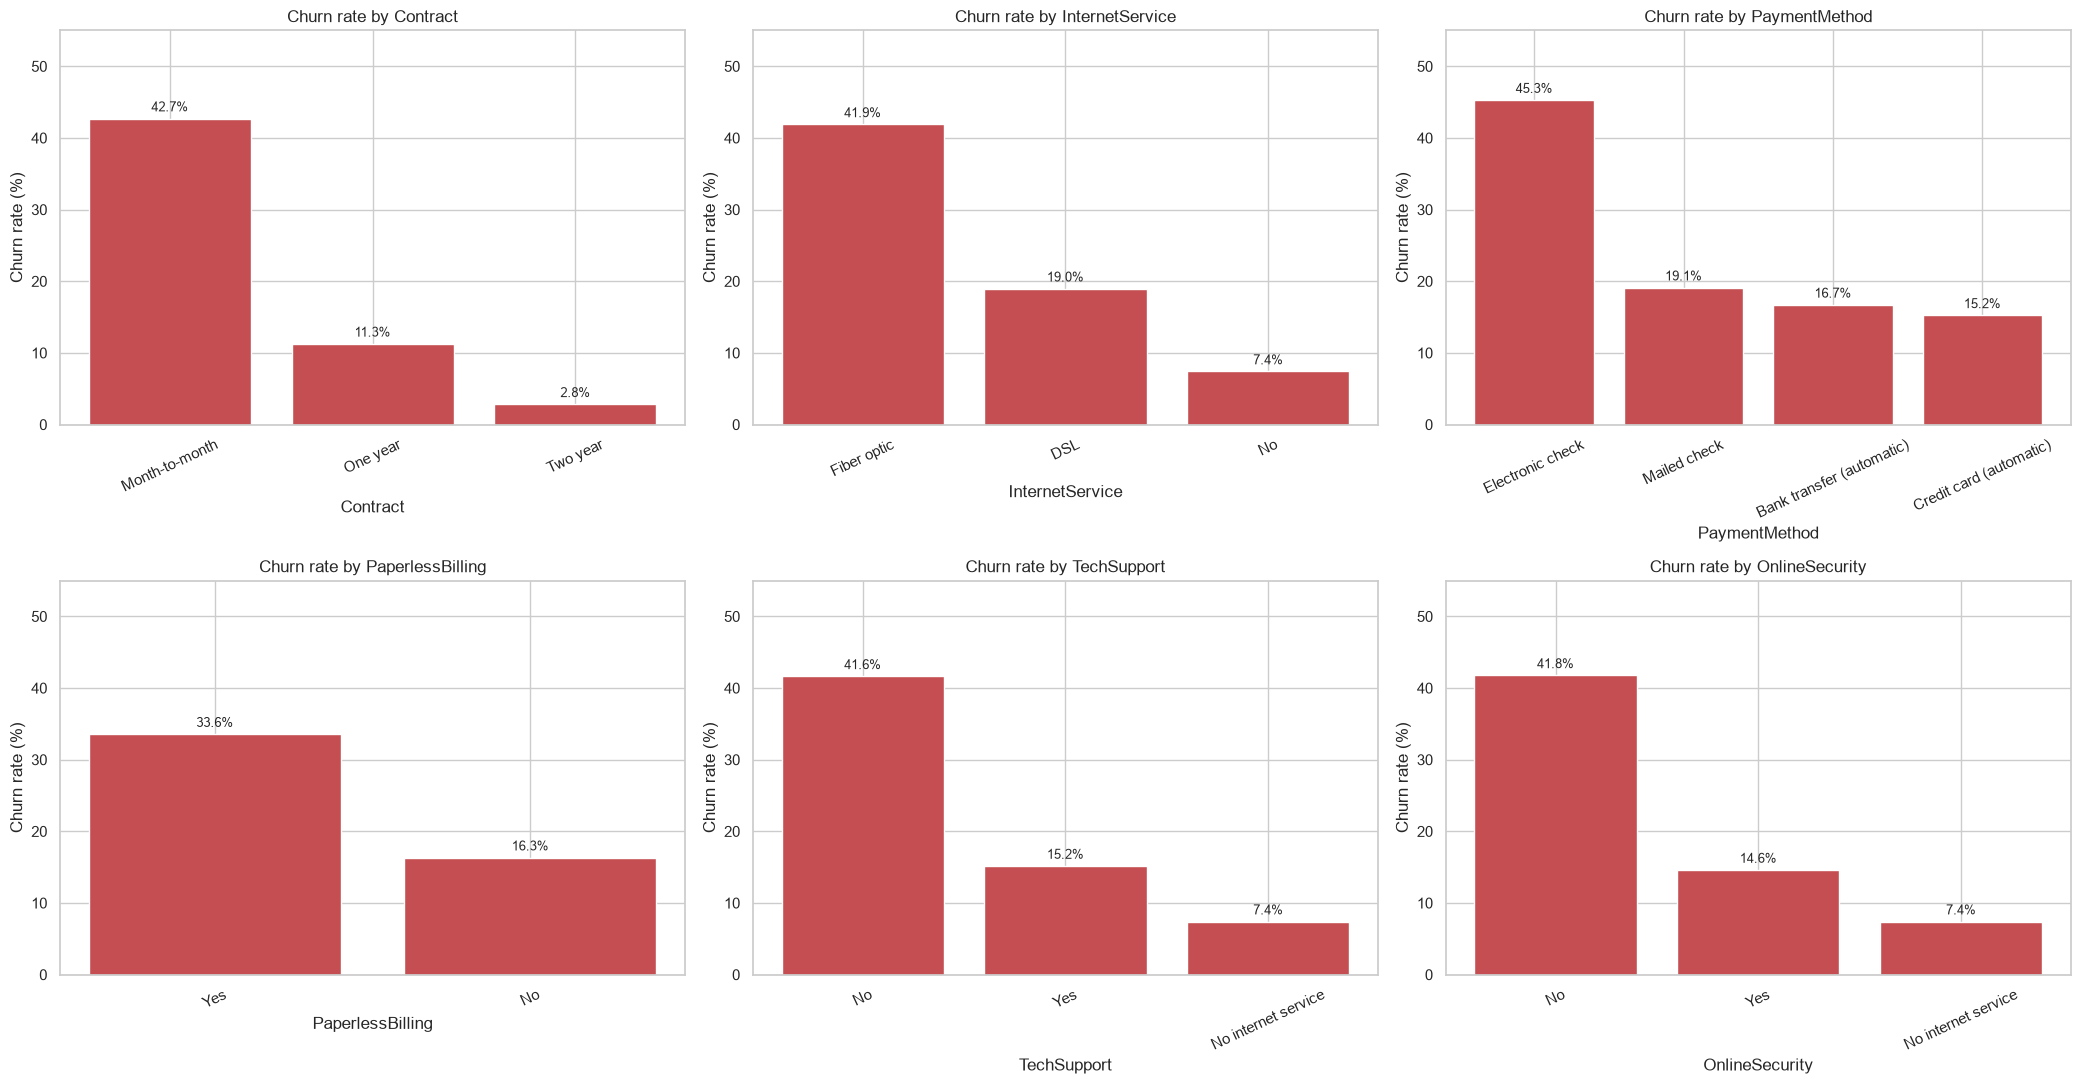

In [14]:
rate_features = ['Contract', 'InternetService', 'PaymentMethod', 'PaperlessBilling', 'TechSupport', 'OnlineSecurity']
fig, axes = plt.subplots(2, 3, figsize=(21, 11))

for ax, column in zip(axes.flatten(), rate_features):
    summary = churn_rate_by(column)
    labels = summary.index.astype(str)
    bars = ax.bar(labels, summary['Churn Rate (%)'], color='#C44E52')
    ax.set_title(f'Churn rate by {column}')
    ax.set_xlabel(column)
    ax.set_ylabel('Churn rate (%)')
    ax.tick_params(axis='x', rotation=25)
    ax.set_ylim(0, max(55, summary['Churn Rate (%)'].max() + 8))
    for bar, value in zip(bars, summary['Churn Rate (%)']):
        ax.text(bar.get_x() + bar.get_width() / 2, value + 1, f'{value:.1f}%', ha='center', fontsize=9)

plt.tight_layout()
plt.show()

## 8. Tenure analysis

Tenure is often one of the strongest churn signals. We group it into business-friendly ranges and compare both customer volume and churn rate within each band.

In [15]:
df['Tenure Band'] = pd.cut(
    df['tenure'],
    bins=[-1, 6, 12, 24, 48, 60, np.inf],
    labels=['0-6', '7-12', '13-24', '25-48', '49-60', '61+'],
    right=True,
)

tenure_summary = df.groupby('Tenure Band', observed=True).agg(
    Customers=('ChurnFlag', 'size'),
    Churned=('ChurnFlag', 'sum'),
)
tenure_summary['Churn Rate (%)'] = tenure_summary['Churned'] / tenure_summary['Customers'] * 100
display(tenure_summary.round(2))

,Customers,Churned,Churn Rate (%)
Tenure Band,,,
0-6,1481,784,52.94
7-12,705,253,35.89
13-24,1024,294,28.71
25-48,1594,325,20.39
49-60,832,120,14.42
61+,1407,93,6.61


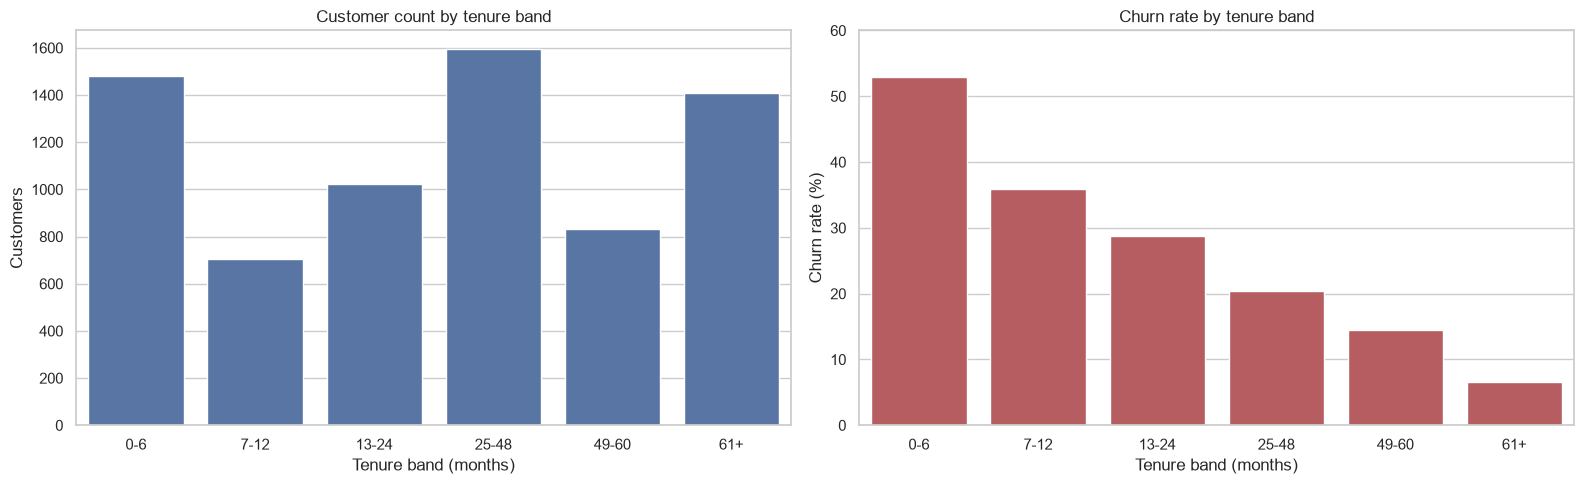

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.barplot(data=tenure_summary, x=tenure_summary.index.astype(str), y='Customers', color='#4C72B0', ax=axes[0])
axes[0].set_title('Customer count by tenure band')
axes[0].set_xlabel('Tenure band (months)')
axes[0].set_ylabel('Customers')

sns.barplot(data=tenure_summary, x=tenure_summary.index.astype(str), y='Churn Rate (%)', color='#C44E52', ax=axes[1])
axes[1].set_title('Churn rate by tenure band')
axes[1].set_xlabel('Tenure band (months)')
axes[1].set_ylabel('Churn rate (%)')
axes[1].set_ylim(0, 60)

plt.tight_layout()
plt.show()

## 9. Numerical differences between churned and retained customers

Grouped statistics make the direction and size of the differences easier to compare than the box plots alone.

In [17]:
numeric_by_churn = df.groupby('Churn')[numeric_columns].agg(['mean', 'median', 'std']).T
display(numeric_by_churn.round(2))

print('Mean monthly charges: churned vs retained')
print(df.groupby('Churn')['MonthlyCharges'].mean().round(2).to_string())

Churn                         No      Yes
tenure           mean      37.57    17.98
                 median    38.00    10.00
                 std       24.11    19.53
MonthlyCharges   mean      61.27    74.44
                 median    64.43    79.65
                 std       31.09    24.67
TotalCharges_num mean   2,555.34 1,531.80
                 median 1,683.60   703.55
                 std    2,329.46 1,890.82

Mean monthly charges: churned vs retained
Churn
No    61.27
Yes   74.44


## 10. Correlation analysis

Pearson correlation measures linear association between numerical variables. It does not establish causation, but it provides a compact view of which numerical variables move together.

,tenure,MonthlyCharges,TotalCharges_num,ChurnFlag
tenure,1.00,0.25,0.83,-0.35
MonthlyCharges,0.25,1.00,0.65,0.19
TotalCharges_num,0.83,0.65,1.00,-0.20
ChurnFlag,-0.35,0.19,-0.20,1.00


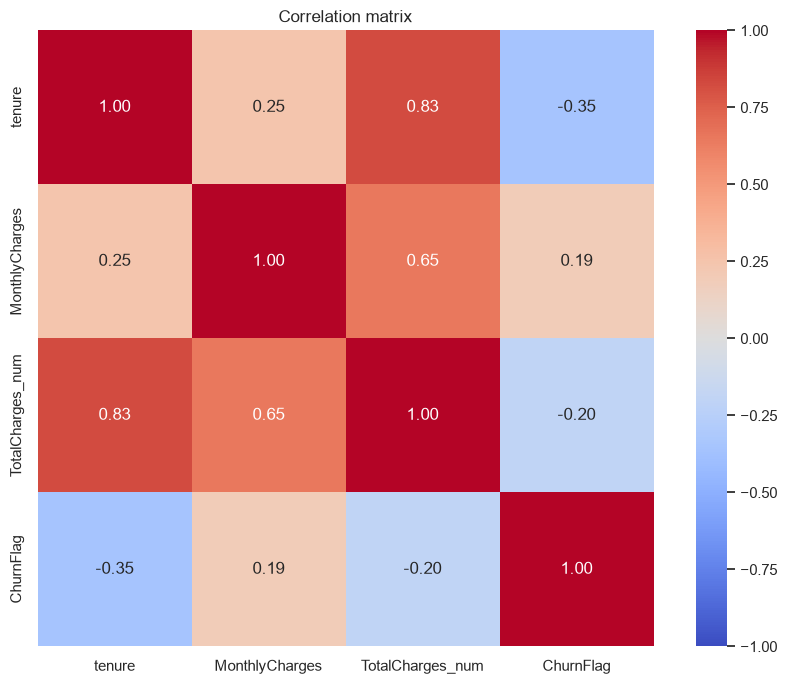

In [18]:
correlation_columns = ['tenure', 'MonthlyCharges', 'TotalCharges_num', 'ChurnFlag']
correlation_matrix = df[correlation_columns].corr()
display(correlation_matrix.round(3))

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    ax=ax,
)
ax.set_title('Correlation matrix')
plt.tight_layout()
plt.show()

## 11. Multivariate patterns

Churn is rarely explained by one variable alone. The following heatmaps combine contract length with internet service and billing choice.

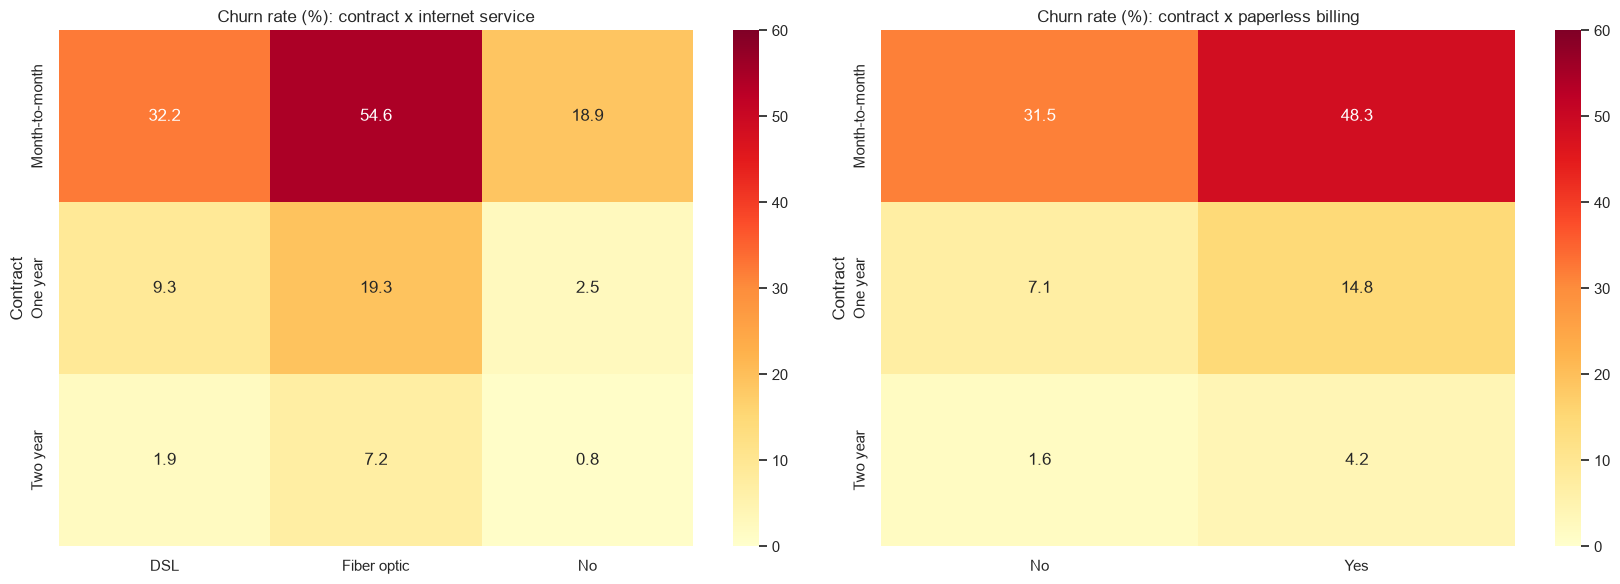

Contract x Internet churn rate (%):


InternetService,DSL,Fiber optic,No
Contract,,,
Month-to-month,32.22,54.61,18.89
One year,9.30,19.29,2.47
Two year,1.91,7.23,0.78



Contract x PaperlessBilling churn rate (%):


PaperlessBilling,No,Yes
Contract,,
Month-to-month,31.50,48.30
One year,7.13,14.75
Two year,1.65,4.20


In [19]:
contract_internet = pd.pivot_table(
    df,
    index='Contract',
    columns='InternetService',
    values='ChurnFlag',
    aggfunc='mean',
    observed=True,
) * 100

contract_paperless = pd.pivot_table(
    df,
    index='Contract',
    columns='PaperlessBilling',
    values='ChurnFlag',
    aggfunc='mean',
    observed=True,
) * 100

fig, axes = plt.subplots(1, 2, figsize=(17, 6))
sns.heatmap(contract_internet, annot=True, fmt='.1f', cmap='YlOrRd', vmin=0, vmax=60, ax=axes[0])
axes[0].set_title('Churn rate (%): contract x internet service')
sns.heatmap(contract_paperless, annot=True, fmt='.1f', cmap='YlOrRd', vmin=0, vmax=60, ax=axes[1])
axes[1].set_title('Churn rate (%): contract x paperless billing')
for ax in axes:
    ax.set_xlabel('')
    ax.set_ylabel('Contract')
plt.tight_layout()
plt.show()

print('Contract x Internet churn rate (%):')
display(contract_internet.round(2))
print('\nContract x PaperlessBilling churn rate (%):')
display(contract_paperless.round(2))

## 12. Demographic patterns

We also examine churn rates for senior-citizen status, partner/dependents, and gender.

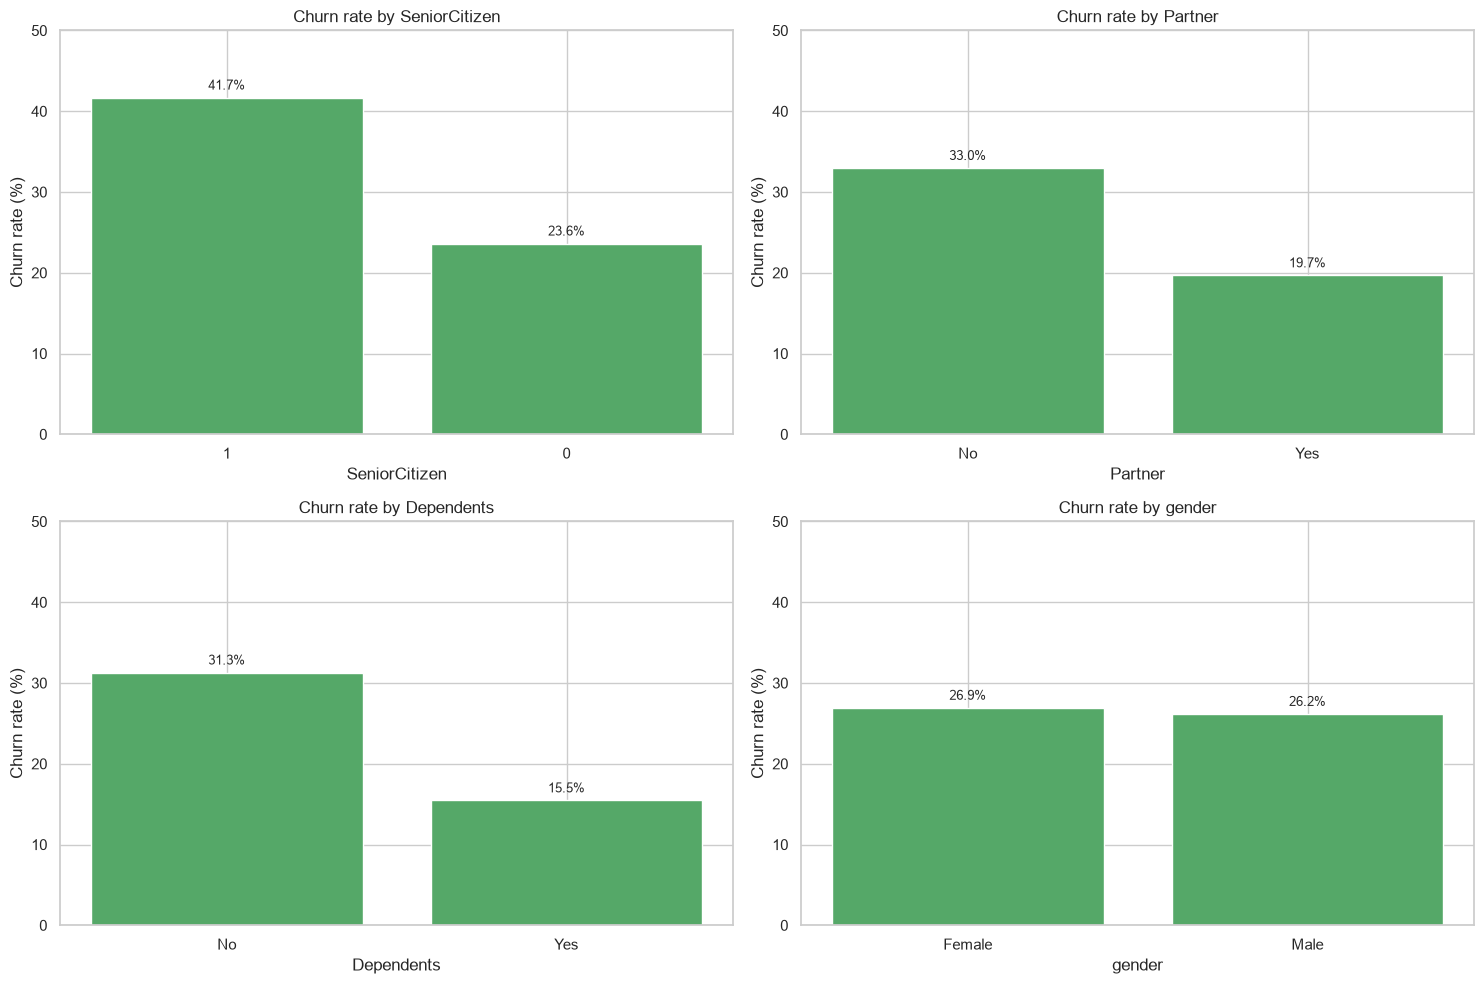

In [20]:
demographic_features = ['SeniorCitizen', 'Partner', 'Dependents', 'gender']
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

for ax, column in zip(axes.flatten(), demographic_features):
    summary = churn_rate_by(column)
    labels = summary.index.astype(str)
    bars = ax.bar(labels, summary['Churn Rate (%)'], color='#55A868')
    ax.set_title(f'Churn rate by {column}')
    ax.set_xlabel(column)
    ax.set_ylabel('Churn rate (%)')
    ax.set_ylim(0, max(50, summary['Churn Rate (%)'].max() + 8))
    for bar, value in zip(bars, summary['Churn Rate (%)']):
        ax.text(bar.get_x() + bar.get_width() / 2, value + 1, f'{value:.1f}%', ha='center', fontsize=9)

plt.tight_layout()
plt.show()

## 13. Key findings

The following observations are based on the current dataset:

1. **Target imbalance:** Approximately 26.5% of customers churn, so model evaluation should not rely on accuracy alone.
2. **Contract length is a major differentiator:** Month-to-month customers churn at about 42.7%, compared with 11.3% for one-year contracts and 2.8% for two-year contracts.
3. **Early-tenure customers churn most:** The 0–6 month tenure band has a churn rate near 52.9%, while customers with 61+ months churn at only about 6.6%.
4. **Fiber-optic customers churn more often:** The churn rate is about 41.9% for fiber optic versus 19.0% for DSL and 7.4% for customers without internet service.
5. **Payment method matters:** Electronic-check customers have a churn rate around 45.3%, materially above the other payment methods.
6. **Support and online security are associated with lower churn:** Customers using tech support have about 15.2% churn versus 41.6% without it; customers with online security have about 14.6% churn versus 41.8% without it.
7. **Higher monthly charges occur among churned customers:** Average monthly charges are approximately $74.44 for churned customers and $61.27 for retained customers.
8. **Some demographic patterns are visible:** Senior citizens and customers without dependents have higher observed churn rates. These are associations and should not be interpreted as causal.
9. **The 11 blank total-charge records are all zero-tenure customers and all stayed.** During preprocessing, these blanks can likely be treated as $0 total charges, but that decision should be made and documented in the modeling stage.

> Correlation and group differences identify useful predictors, but they do not prove that changing a characteristic will cause a customer to stay.

## 14. Recommended next stage

The EDA suggests the following preprocessing and modeling plan:

1. Drop `customerID` because it identifies customers rather than describing behavior.
2. Resolve the 11 blank `TotalCharges` values, most likely as zero totals for new customers.
3. Treat `SeniorCitizen` as categorical rather than a continuous measurement.
4. One-hot encode nominal variables; scale numerical variables for Logistic Regression, KNN, and SVM.
5. Create a stratified train/test split because of target imbalance.
6. Train and compare Logistic Regression, Decision Tree, Random Forest, KNN, SVM, XGBoost, and Gradient Boosting.
7. Compare models using cross-validation, precision, recall, F1, ROC AUC, and confusion matrices—not accuracy alone.
8. Tune the strongest models and inspect feature importance or coefficients to verify that the models align with the EDA findings.

# Machine Learning Modeling

This section builds and evaluates predictive models for customer churn.

**Models:**
- Traditional ML: Logistic Regression, Random Forest, XGBoost (with hyperparameter tuning via RandomizedSearchCV)
- Deep Learning: Three ANN architectures with different hidden-layer sizes

**Evaluation metrics:** Accuracy, Precision, Recall, F1-score, ROC-AUC, Confusion Matrix

## 1. Data Preprocessing for Modeling

In [21]:
# Reload the raw data fresh for modeling
import pandas as pd
import numpy as np
from pathlib import Path

DATA_FILENAME = 'WA_Fn-UseC_-Telco-Customer-Churn.csv'
data_path = Path.cwd() / DATA_FILENAME
df_raw = pd.read_csv(data_path)
print(f'Raw shape: {df_raw.shape}')

# Drop the 11 rows where TotalCharges is blank (tenure=0, all stayed)
df = df_raw[df_raw['TotalCharges'].astype(str).str.strip() != ''].copy()
print(f'After dropping blank TotalCharges: {df.shape}')

# Convert TotalCharges to numeric
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

# Drop customerID (not predictive)
df = df.drop(columns=['customerID'])

# Convert SeniorCitizen to categorical (object) for proper encoding
df['SeniorCitizen'] = df['SeniorCitizen'].astype('object')

# Target encoding
df['Churn'] = df['Churn'].map({'No': 0, 'Yes': 1})

print(f'Final modeling dataset shape: {df.shape}')
print(f"Churn distribution:\n{df["Churn"].value_counts()}")
print(f"Churn rate: {df["Churn"].mean():.2%}")

Raw shape: (7043, 21)
After dropping blank TotalCharges: (7032, 21)
Final modeling dataset shape: (7032, 20)
Churn distribution:
Churn
0    5163
1    1869
Name: count, dtype: int64
Churn rate: 26.58%


## 2. Stratified Train/Test Split

In [22]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=['Churn'])
y = df['Churn']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f'Train: {X_train.shape[0]:,} | Test: {X_test.shape[0]:,}')
print(f'Train churn rate: {y_train.mean():.2%} | Test churn rate: {y_test.mean():.2%}')

Train: 5,625 | Test: 1,407
Train churn rate: 26.58% | Test churn rate: 26.58%


## 3. Preprocessing Pipeline (ColumnTransformer)

In [23]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Identify column types
numeric_features = ['tenure', 'MonthlyCharges', 'TotalCharges']
categorical_features = [col for col in X.columns if col not in numeric_features]

print(f'Numeric features ({len(numeric_features)}): {numeric_features}')
print(f'Categorical features ({len(categorical_features)}): {categorical_features}')

# Build preprocessor
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False), categorical_features)
    ],
    remainder='passthrough'
)

# Fit on train, transform both
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print(f'Processed train shape: {X_train_processed.shape}')
print(f'Processed test shape: {X_test_processed.shape}')

# Get feature names after one-hot encoding
cat_encoder = preprocessor.named_transformers_['cat']
cat_feature_names = cat_encoder.get_feature_names_out(categorical_features)
feature_names = list(numeric_features) + list(cat_feature_names)
print(f'Total features after encoding: {len(feature_names)}')

Numeric features (3): ['tenure', 'MonthlyCharges', 'TotalCharges']
Categorical features (16): ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
Processed train shape: (5625, 30)
Processed test shape: (1407, 30)
Total features after encoding: 30


## 4. Model Evaluation Utility

In [24]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, 
    f1_score, roc_auc_score, confusion_matrix, classification_report
)
import seaborn as sns
import matplotlib.pyplot as plt

def evaluate_model(model, X_test, y_test, model_name='Model'):
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1] if hasattr(model, 'predict_proba') else None
    
    metrics = {
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1': f1_score(y_test, y_pred),
        'ROC-AUC': roc_auc_score(y_test, y_prob) if y_prob is not None else None
    }
    
    print(f'\n{"="*50}')
    print(f'{model_name} Performance')
    print(f'{"="*50}')
    for k, v in metrics.items():
        if v is not None:
            print(f'{k:12s}: {v:.4f}')
    
    print(f'\nConfusion Matrix:')
    cm = confusion_matrix(y_test, y_pred)
    print(cm)
    
    fig, ax = plt.subplots(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
                xticklabels=['No Churn', 'Churn'], 
                yticklabels=['No Churn', 'Churn'], ax=ax)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')
    ax.set_title(f'{model_name} - Confusion Matrix')
    plt.tight_layout()
    plt.show()
    
    print(f'\nClassification Report:')
    print(classification_report(y_test, y_pred, target_names=['No Churn', 'Churn']))
    
    return metrics, y_pred, y_prob

def print_cv_results(search, model_name):
    print(f'\n{model_name} - Best Parameters:')
    for k, v in search.best_params_.items():
        print(f'  {k}: {v}')
    print(f'Best CV ROC-AUC: {search.best_score_:.4f}')

## 5. Logistic Regression with RandomizedSearchCV

Fitting 5 folds for each of 50 candidates, totalling 250 fits



Logistic Regression - Best Parameters:
  C: 12.164139351417068
  class_weight: None
  solver: saga
Best CV ROC-AUC: 0.8463

Logistic Regression Performance
Accuracy    : 0.8003
Precision   : 0.6388
Recall      : 0.5722
F1          : 0.6037
ROC-AUC     : 0.8352

Confusion Matrix:
[[912 121]
 [160 214]]


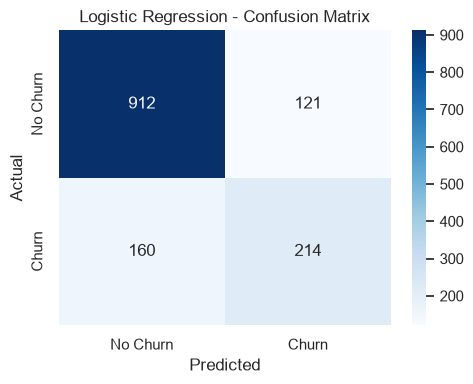


Classification Report:
              precision    recall  f1-score   support

    No Churn       0.85      0.88      0.87      1033
       Churn       0.64      0.57      0.60       374

    accuracy                           0.80      1407
   macro avg       0.74      0.73      0.74      1407
weighted avg       0.79      0.80      0.80      1407



In [25]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from scipy.stats import loguniform

# Base pipeline
lr_pipe = LogisticRegression(
    penalty='l2',
    solver='lbfgs',
    max_iter=1000,
    random_state=42,
    n_jobs=-1
)

# Parameter distribution
param_dist_lr = {
    'C': loguniform(0.01, 100),
    'class_weight': [None, 'balanced'],
    'solver': ['lbfgs', 'saga']
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

lr_search = RandomizedSearchCV(
    lr_pipe, param_dist_lr,
    n_iter=50,
    scoring='roc_auc',
    cv=cv,
    n_jobs=-1,
    random_state=42,
    verbose=1
)

lr_search.fit(X_train_processed, y_train)
print_cv_results(lr_search, 'Logistic Regression')

best_lr = lr_search.best_estimator_
lr_metrics, lr_pred, lr_prob = evaluate_model(best_lr, X_test_processed, y_test, 'Logistic Regression')

## 6. Random Forest with RandomizedSearchCV

Fitting 5 folds for each of 60 candidates, totalling 300 fits



Random Forest - Best Parameters:
  n_estimators: 200
  min_samples_split: 5
  min_samples_leaf: 4
  max_features: sqrt
  max_depth: 10
  class_weight: balanced
Best CV ROC-AUC: 0.8484

Random Forest Performance
Accuracy    : 0.7512
Precision   : 0.5208
Recall      : 0.8048
F1          : 0.6324
ROC-AUC     : 0.8382

Confusion Matrix:
[[756 277]
 [ 73 301]]


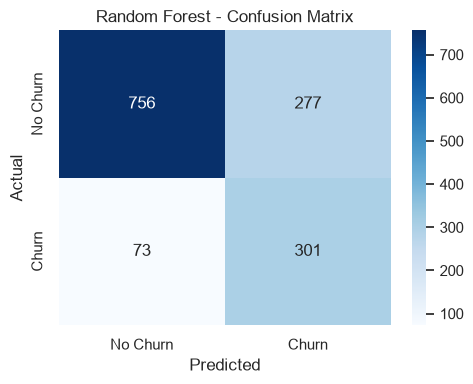


Classification Report:
              precision    recall  f1-score   support

    No Churn       0.91      0.73      0.81      1033
       Churn       0.52      0.80      0.63       374

    accuracy                           0.75      1407
   macro avg       0.72      0.77      0.72      1407
weighted avg       0.81      0.75      0.76      1407



In [26]:
from sklearn.ensemble import RandomForestClassifier
from scipy.stats import randint

rf_pipe = RandomForestClassifier(random_state=42, n_jobs=-1)

param_dist_rf = {
    'n_estimators': [100, 200, 300, 400],
    'max_depth': [5, 10, 15, 20, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': ['sqrt', 'log2', None],
    'class_weight': [None, 'balanced', 'balanced_subsample']
}

rf_search = RandomizedSearchCV(
    rf_pipe, param_dist_rf,
    n_iter=60,
    scoring='roc_auc',
    cv=cv,
    n_jobs=-1,
    random_state=42,
    verbose=1
)

rf_search.fit(X_train_processed, y_train)
print_cv_results(rf_search, 'Random Forest')

best_rf = rf_search.best_estimator_
rf_metrics, rf_pred, rf_prob = evaluate_model(best_rf, X_test_processed, y_test, 'Random Forest')

## 7. XGBoost with RandomizedSearchCV

scale_pos_weight (neg/pos ratio): 2.76
Fitting 5 folds for each of 60 candidates, totalling 300 fits



XGBoost - Best Parameters:
  subsample: 0.7
  scale_pos_weight: 2.762541806020067
  reg_lambda: 5
  reg_alpha: 0.5
  n_estimators: 300
  max_depth: 5
  learning_rate: 0.01
  gamma: 0
  colsample_bytree: 0.7
Best CV ROC-AUC: 0.8499

XGBoost Performance
Accuracy    : 0.7406
Precision   : 0.5076
Recall      : 0.8075
F1          : 0.6233
ROC-AUC     : 0.8415

Confusion Matrix:
[[740 293]
 [ 72 302]]


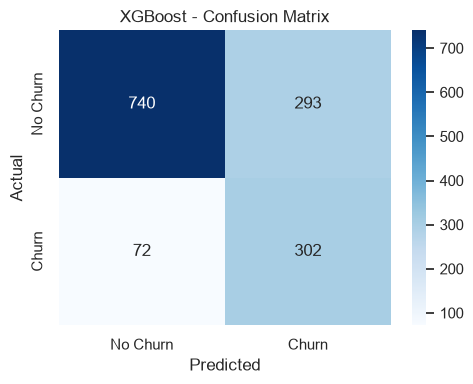


Classification Report:
              precision    recall  f1-score   support

    No Churn       0.91      0.72      0.80      1033
       Churn       0.51      0.81      0.62       374

    accuracy                           0.74      1407
   macro avg       0.71      0.76      0.71      1407
weighted avg       0.80      0.74      0.75      1407



In [27]:
from xgboost import XGBClassifier

# Calculate scale_pos_weight for class imbalance
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
print(f'scale_pos_weight (neg/pos ratio): {scale_pos_weight:.2f}')

xgb_pipe = XGBClassifier(
    objective='binary:logistic',
    eval_metric='auc',
    random_state=42,
    n_jobs=-1,
    verbosity=0
)

param_dist_xgb = {
    'n_estimators': [100, 200, 300, 400],
    'max_depth': [3, 5, 7, 9],
    'learning_rate': [0.01, 0.05, 0.1, 0.2],
    'subsample': [0.7, 0.8, 0.9, 1.0],
    'colsample_bytree': [0.7, 0.8, 0.9, 1.0],
    'gamma': [0, 0.1, 0.2, 0.5],
    'reg_alpha': [0, 0.1, 0.5, 1],
    'reg_lambda': [1, 1.5, 2, 5],
    'scale_pos_weight': [1, scale_pos_weight]
}

xgb_search = RandomizedSearchCV(
    xgb_pipe, param_dist_xgb,
    n_iter=60,
    scoring='roc_auc',
    cv=cv,
    n_jobs=-1,
    random_state=42,
    verbose=1
)

xgb_search.fit(X_train_processed, y_train)
print_cv_results(xgb_search, 'XGBoost')

best_xgb = xgb_search.best_estimator_
xgb_metrics, xgb_pred, xgb_prob = evaluate_model(best_xgb, X_test_processed, y_test, 'XGBoost')

## 8. Traditional Models Comparison


Traditional Models Comparison:


,Accuracy,Precision,Recall,F1,ROC-AUC
Logistic Regression,0.80,0.64,0.57,0.60,0.84
Random Forest,0.75,0.52,0.80,0.63,0.84
XGBoost,0.74,0.51,0.81,0.62,0.84


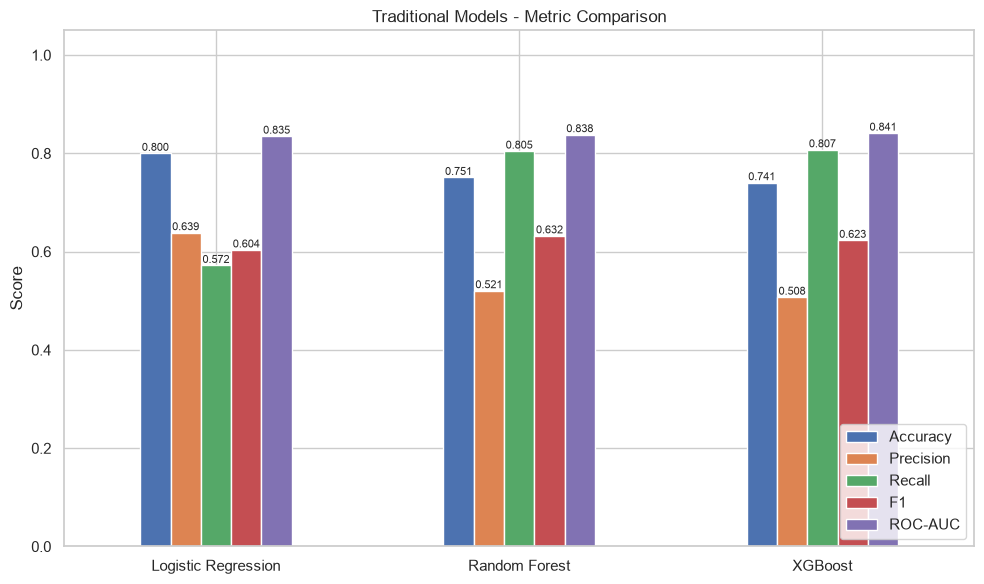

In [28]:
import pandas as pd

traditional_results = pd.DataFrame({
    'Logistic Regression': lr_metrics,
    'Random Forest': rf_metrics,
    'XGBoost': xgb_metrics
}).T

print('\nTraditional Models Comparison:')
display(traditional_results.round(4))

# Bar plot comparison
fig, ax = plt.subplots(figsize=(10, 6))
traditional_results[['Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC']].plot(kind='bar', ax=ax)
ax.set_title('Traditional Models - Metric Comparison')
ax.set_ylabel('Score')
ax.set_ylim(0, 1.05)
ax.legend(loc='lower right')
ax.tick_params(axis='x', rotation=0)
for container in ax.containers:
    ax.bar_label(container, fmt='%.3f', fontsize=8)
plt.tight_layout()
plt.show()

## 9. Feature Importance (Tree-Based Models)

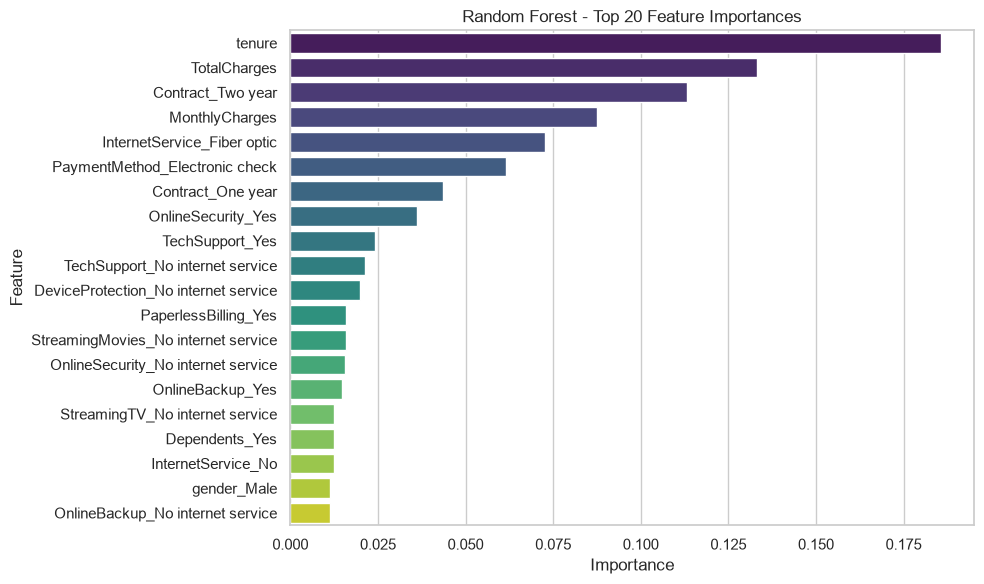

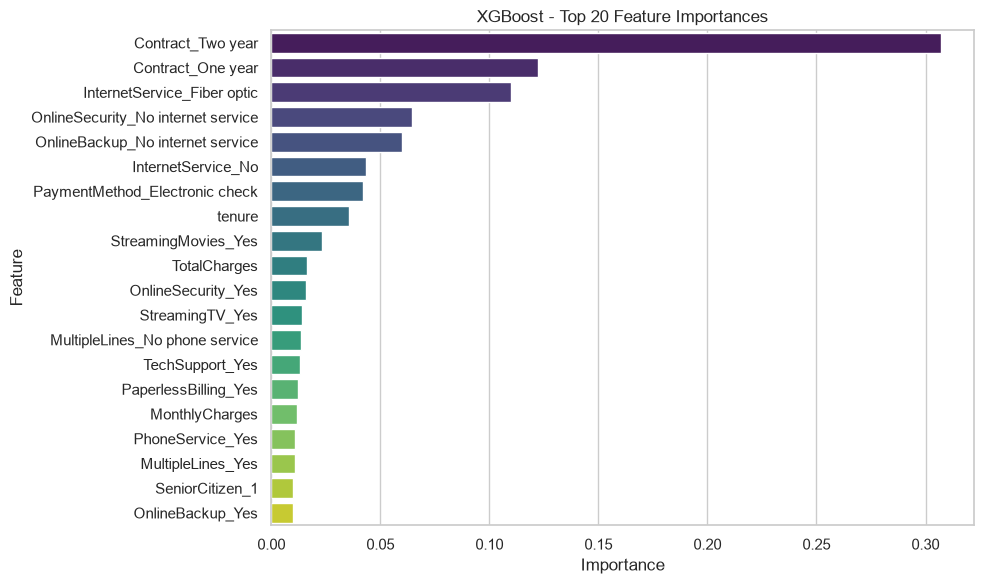

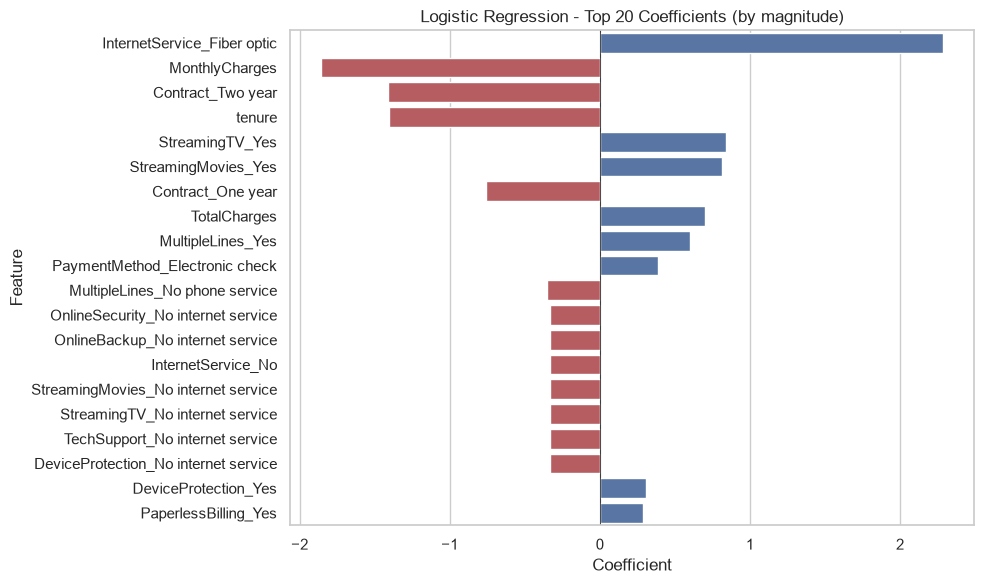

In [29]:
def plot_feature_importance(model, feature_names, model_name, top_n=20):
    """Plot top N feature importances."""
    if hasattr(model, 'feature_importances_'):
        importances = model.feature_importances_
    elif hasattr(model, 'coef_'):
        importances = np.abs(model.coef_[0])
    else:
        print(f'{model_name} does not have feature_importances_ or coef_')
        return
    
    fi_df = pd.DataFrame({'Feature': feature_names, 'Importance': importances})
    fi_df = fi_df.sort_values('Importance', ascending=False).head(top_n)
    
    fig, ax = plt.subplots(figsize=(10, max(6, top_n * 0.3)))
    sns.barplot(data=fi_df, y='Feature', x='Importance', palette='viridis', ax=ax)
    ax.set_title(f'{model_name} - Top {top_n} Feature Importances')
    ax.set_xlabel('Importance')
    plt.tight_layout()
    plt.show()

plot_feature_importance(best_rf, feature_names, 'Random Forest', top_n=20)
plot_feature_importance(best_xgb, feature_names, 'XGBoost', top_n=20)

# Logistic Regression coefficients
lr_coef = pd.DataFrame({'Feature': feature_names, 'Coefficient': best_lr.coef_[0]})
lr_coef = lr_coef.sort_values('Coefficient', key=abs, ascending=False).head(20)
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(data=lr_coef, y='Feature', x='Coefficient', 
            palette=['#C44E52' if c < 0 else '#4C72B0' for c in lr_coef['Coefficient']], ax=ax)
ax.set_title('Logistic Regression - Top 20 Coefficients (by magnitude)')
ax.axvline(0, color='black', linewidth=0.5)
plt.tight_layout()
plt.show()

# Artificial Neural Network Models

We build three ANN architectures with different hidden-layer configurations:
- **ANN-1**: Input(19) -> Hidden(32, ReLU) -> Hidden(16, ReLU) -> Output(1, Sigmoid)
- **ANN-2**: Input(19) -> Hidden(16, ReLU) -> Hidden(8, ReLU) -> Output(1, Sigmoid)
- **ANN-3**: Input(19) -> Hidden(64, ReLU) -> Hidden(32, ReLU) -> Hidden(16, ReLU) -> Output(1, Sigmoid)

**Shared settings:**
- Optimizer: Adam
- Loss: Binary Crossentropy
- Batch size: 32
- Epochs: 100 (with early stopping, patience=10, restore_best_weights=True)
- Validation split: 20%

In [30]:
# Prepare data for Keras (already preprocessed via ColumnTransformer)
# We need to ensure the input dimension matches

import os
os.environ['TF_ENABLE_ONEDNN_OPTS'] = '0'
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'

import tensorflow as tf
# Use keras 3 directly (bundled with TF)
from keras.models import Sequential
from keras.layers import Dense, Input, Dropout
from keras.optimizers import Adam
from keras.callbacks import EarlyStopping
from keras.regularizers import l2

print(f'TensorFlow version: {tf.__version__}')
print(f'Keras version: {tf.keras.__version__}')
print(f'Input dimension: {X_train_processed.shape[1]}')

# Verify we have the right input dim (should be 19 original -> more after one-hot)
# Actually let's check the original feature count before encoding
original_numeric = 3
original_categorical = len(categorical_features)
print(f'Original numeric: {original_numeric}, Original categorical: {original_categorical}')
print(f'Expected one-hot features: ~{X_train_processed.shape[1]}')

# Create a validation split from training data
from sklearn.model_selection import train_test_split
X_train_ann, X_val_ann, y_train_ann, y_val_ann = train_test_split(
    X_train_processed, y_train, test_size=0.2, random_state=42, stratify=y_train
)

print(f'ANN Train: {X_train_ann.shape[0]}, Val: {X_val_ann.shape[0]}, Test: {X_test_processed.shape[0]}')

TensorFlow version: 2.21.0
Keras version: 3.15.1
Input dimension: 30
Original numeric: 3, Original categorical: 16
Expected one-hot features: ~30
ANN Train: 4500, Val: 1125, Test: 1407


In [31]:
def build_ann(hidden_layers, input_dim, dropout_rate=0.3, l2_reg=0.01):
    """
    Build ANN with specified hidden layer sizes.
    
    Args:
        hidden_layers: list of ints, e.g., [32, 16] or [64, 32, 16]
        input_dim: int, number of input features
        dropout_rate: float, dropout after each hidden layer
        l2_reg: float, L2 regularization strength
    """
    model = Sequential()
    
    # Input layer
    model.add(Input(shape=(input_dim,)))
    
    # Hidden layers
    for i, units in enumerate(hidden_layers):
        model.add(Dense(
            units, 
            activation='relu',
            kernel_regularizer=l2(l2_reg),
            name=f'hidden_{i+1}'
        ))
        if dropout_rate > 0:
            model.add(Dropout(dropout_rate, name=f'dropout_{i+1}'))
    
    # Output layer
    model.add(Dense(1, activation='sigmoid', name='output'))
    
    model.compile(
        optimizer=Adam(learning_rate=0.001),
        loss='binary_crossentropy',
        metrics=['accuracy', tf.keras.metrics.AUC(name='auc')]
    )
    
    return model

# Early stopping callback
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True,
    verbose=1
)

# Test model summaries
for name, layers in [('ANN-1 (32,16)', [32, 16]), 
                      ('ANN-2 (16,8)', [16, 8]), 
                      ('ANN-3 (64,32,16)', [64, 32, 16])]:
    print(f'\n{name}:')
    model = build_ann(layers, X_train_ann.shape[1])
    model.summary()


ANN-1 (32,16):


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ hidden_1 (Dense)                │ (None, 32)             │           992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_2 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,537 (6.00 KB)

 Trainable params: 1,537 (6.00 KB)

 Non-trainable params: 0 (0.00 B)

... (8 outputs left out)

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ hidden_1 (Dense)                │ (None, 64)             │         1,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_2 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_3 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,609 (18.00 KB)

 Trainable params: 4,609 (18.00 KB)

 Non-trainable params: 0 (0.00 B)

## 13. Train ANN-1: Hidden Layers [32, 16]

Epoch 1/100


  1/141 ━━━━━━━━━━━━━━━━━━━━ 2:46 1s/step - accuracy: 0.6250 - auc: 0.5148 - loss: 1.1704

 59/141 ━━━━━━━━━━━━━━━━━━━━ 0s 871us/step - accuracy: 0.6933 - auc: 0.6331 - loss: 1.0282

117/141 ━━━━━━━━━━━━━━━━━━━━ 0s 870us/step - accuracy: 0.7236 - auc: 0.6940 - loss: 0.9355

141/141 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.7300 - auc: 0.7082 - loss: 0.9117 - val_accuracy: 0.7796 - val_auc: 0.8072 - val_loss: 0.7320


Epoch 2/100


... (192 outputs left out)

Epoch 38: early stopping


Restoring model weights from the end of the best epoch: 28.



ANN-1 Test Results:
  Loss: 0.4438
  Accuracy: 0.8024
  AUC: 0.8374



ANN-1 Detailed Metrics:
  Accuracy    : 0.8024
  Precision   : 0.6569
  Recall      : 0.5374
  F1          : 0.5912
  ROC-AUC     : 0.8376


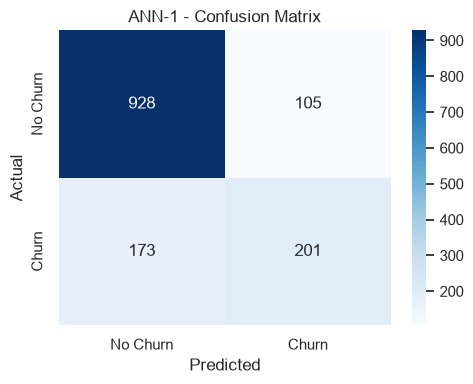

              precision    recall  f1-score   support

    No Churn       0.84      0.90      0.87      1033
       Churn       0.66      0.54      0.59       374

    accuracy                           0.80      1407
   macro avg       0.75      0.72      0.73      1407
weighted avg       0.79      0.80      0.80      1407



In [32]:
# ANN-1: 32, 16
ann1 = build_ann([32, 16], X_train_ann.shape[1])

history_ann1 = ann1.fit(
    X_train_ann, y_train_ann,
    validation_data=(X_val_ann, y_val_ann),
    epochs=100,
    batch_size=32,
    callbacks=[early_stopping],
    verbose=1
)

# Evaluate on test set
ann1_test_results = ann1.evaluate(X_test_processed, y_test, verbose=0)
print(f'\nANN-1 Test Results:')
print(f'  Loss: {ann1_test_results[0]:.4f}')
print(f'  Accuracy: {ann1_test_results[1]:.4f}')
print(f'  AUC: {ann1_test_results[2]:.4f}')

# Predictions for detailed metrics
y_prob_ann1 = ann1.predict(X_test_processed, verbose=0).flatten()
y_pred_ann1 = (y_prob_ann1 > 0.5).astype(int)

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, classification_report

ann1_metrics = {
    'Accuracy': accuracy_score(y_test, y_pred_ann1),
    'Precision': precision_score(y_test, y_pred_ann1),
    'Recall': recall_score(y_test, y_pred_ann1),
    'F1': f1_score(y_test, y_pred_ann1),
    'ROC-AUC': roc_auc_score(y_test, y_prob_ann1)
}

print(f'\nANN-1 Detailed Metrics:')
for k, v in ann1_metrics.items():
    print(f'  {k:12s}: {v:.4f}')

cm = confusion_matrix(y_test, y_pred_ann1)
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['No Churn', 'Churn'], 
            yticklabels=['No Churn', 'Churn'], ax=ax)
ax.set_xlabel('Predicted')
ax.set_ylabel('Actual')
ax.set_title('ANN-1 - Confusion Matrix')
plt.tight_layout()
plt.show()

print(classification_report(y_test, y_pred_ann1, target_names=['No Churn', 'Churn']))

## 14. Train ANN-2: Hidden Layers [16, 8]

Epoch 1/100


  1/141 ━━━━━━━━━━━━━━━━━━━━ 1:56 832ms/step - accuracy: 0.6875 - auc: 0.6039 - loss: 1.0056

 51/141 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.6005 - auc: 0.5652 - loss: 0.9405    

106/141 ━━━━━━━━━━━━━━━━━━━━ 0s 959us/step - accuracy: 0.6536 - auc: 0.6041 - loss: 0.8730

141/141 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.6664 - auc: 0.6145 - loss: 0.8431 - val_accuracy: 0.7342 - val_auc: 0.8057 - val_loss: 0.6892


Epoch 2/100


... (292 outputs left out)

Epoch 59: early stopping


Restoring model weights from the end of the best epoch: 49.



ANN-2 Test Results:
  Loss: 0.4489
  Accuracy: 0.8031
  AUC: 0.8363



ANN-2 Detailed Metrics:
  Accuracy    : 0.8031
  Precision   : 0.6431
  Recall      : 0.5829
  F1          : 0.6115
  ROC-AUC     : 0.8364


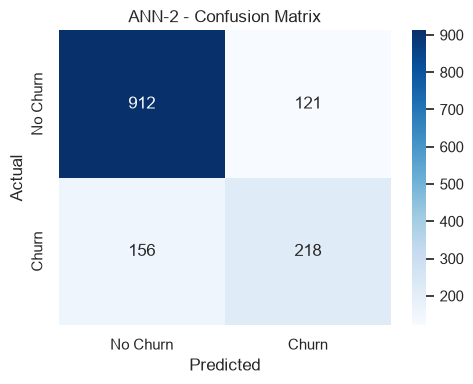

              precision    recall  f1-score   support

    No Churn       0.85      0.88      0.87      1033
       Churn       0.64      0.58      0.61       374

    accuracy                           0.80      1407
   macro avg       0.75      0.73      0.74      1407
weighted avg       0.80      0.80      0.80      1407



In [33]:
# ANN-2: 16, 8
ann2 = build_ann([16, 8], X_train_ann.shape[1])

history_ann2 = ann2.fit(
    X_train_ann, y_train_ann,
    validation_data=(X_val_ann, y_val_ann),
    epochs=100,
    batch_size=32,
    callbacks=[early_stopping],
    verbose=1
)

ann2_test_results = ann2.evaluate(X_test_processed, y_test, verbose=0)
print(f'\nANN-2 Test Results:')
print(f'  Loss: {ann2_test_results[0]:.4f}')
print(f'  Accuracy: {ann2_test_results[1]:.4f}')
print(f'  AUC: {ann2_test_results[2]:.4f}')

y_prob_ann2 = ann2.predict(X_test_processed, verbose=0).flatten()
y_pred_ann2 = (y_prob_ann2 > 0.5).astype(int)

ann2_metrics = {
    'Accuracy': accuracy_score(y_test, y_pred_ann2),
    'Precision': precision_score(y_test, y_pred_ann2),
    'Recall': recall_score(y_test, y_pred_ann2),
    'F1': f1_score(y_test, y_pred_ann2),
    'ROC-AUC': roc_auc_score(y_test, y_prob_ann2)
}

print(f'\nANN-2 Detailed Metrics:')
for k, v in ann2_metrics.items():
    print(f'  {k:12s}: {v:.4f}')

cm = confusion_matrix(y_test, y_pred_ann2)
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['No Churn', 'Churn'], 
            yticklabels=['No Churn', 'Churn'], ax=ax)
ax.set_xlabel('Predicted')
ax.set_ylabel('Actual')
ax.set_title('ANN-2 - Confusion Matrix')
plt.tight_layout()
plt.show()

print(classification_report(y_test, y_pred_ann2, target_names=['No Churn', 'Churn']))

## 15. Train ANN-3: Hidden Layers [64, 32, 16] (3 hidden layers)

Epoch 1/100


  1/141 ━━━━━━━━━━━━━━━━━━━━ 2:29 1s/step - accuracy: 0.4062 - auc: 0.3846 - loss: 1.7920

 54/141 ━━━━━━━━━━━━━━━━━━━━ 0s 954us/step - accuracy: 0.6464 - auc: 0.5726 - loss: 1.5085

108/141 ━━━━━━━━━━━━━━━━━━━━ 0s 952us/step - accuracy: 0.6863 - auc: 0.6576 - loss: 1.3324

141/141 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7040 - auc: 0.6950 - loss: 1.2398 - val_accuracy: 0.7662 - val_auc: 0.8184 - val_loss: 0.8855


Epoch 2/100


... (279 outputs left out)

Epoch 56: early stopping


Restoring model weights from the end of the best epoch: 46.



ANN-3 Test Results:
  Loss: 0.4541
  Accuracy: 0.8017
  AUC: 0.8369



ANN-3 Detailed Metrics:
  Accuracy    : 0.8017
  Precision   : 0.6578
  Recall      : 0.5294
  F1          : 0.5867
  ROC-AUC     : 0.8375


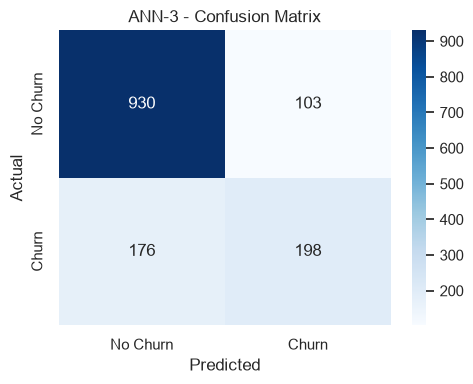

              precision    recall  f1-score   support

    No Churn       0.84      0.90      0.87      1033
       Churn       0.66      0.53      0.59       374

    accuracy                           0.80      1407
   macro avg       0.75      0.71      0.73      1407
weighted avg       0.79      0.80      0.79      1407



In [34]:
# ANN-3: 64, 32, 16
ann3 = build_ann([64, 32, 16], X_train_ann.shape[1])

history_ann3 = ann3.fit(
    X_train_ann, y_train_ann,
    validation_data=(X_val_ann, y_val_ann),
    epochs=100,
    batch_size=32,
    callbacks=[early_stopping],
    verbose=1
)

ann3_test_results = ann3.evaluate(X_test_processed, y_test, verbose=0)
print(f'\nANN-3 Test Results:')
print(f'  Loss: {ann3_test_results[0]:.4f}')
print(f'  Accuracy: {ann3_test_results[1]:.4f}')
print(f'  AUC: {ann3_test_results[2]:.4f}')

y_prob_ann3 = ann3.predict(X_test_processed, verbose=0).flatten()
y_pred_ann3 = (y_prob_ann3 > 0.5).astype(int)

ann3_metrics = {
    'Accuracy': accuracy_score(y_test, y_pred_ann3),
    'Precision': precision_score(y_test, y_pred_ann3),
    'Recall': recall_score(y_test, y_pred_ann3),
    'F1': f1_score(y_test, y_pred_ann3),
    'ROC-AUC': roc_auc_score(y_test, y_prob_ann3)
}

print(f'\nANN-3 Detailed Metrics:')
for k, v in ann3_metrics.items():
    print(f'  {k:12s}: {v:.4f}')

cm = confusion_matrix(y_test, y_pred_ann3)
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['No Churn', 'Churn'], 
            yticklabels=['No Churn', 'Churn'], ax=ax)
ax.set_xlabel('Predicted')
ax.set_ylabel('Actual')
ax.set_title('ANN-3 - Confusion Matrix')
plt.tight_layout()
plt.show()

print(classification_report(y_test, y_pred_ann3, target_names=['No Churn', 'Churn']))

## 16. ANN Training Curves Comparison

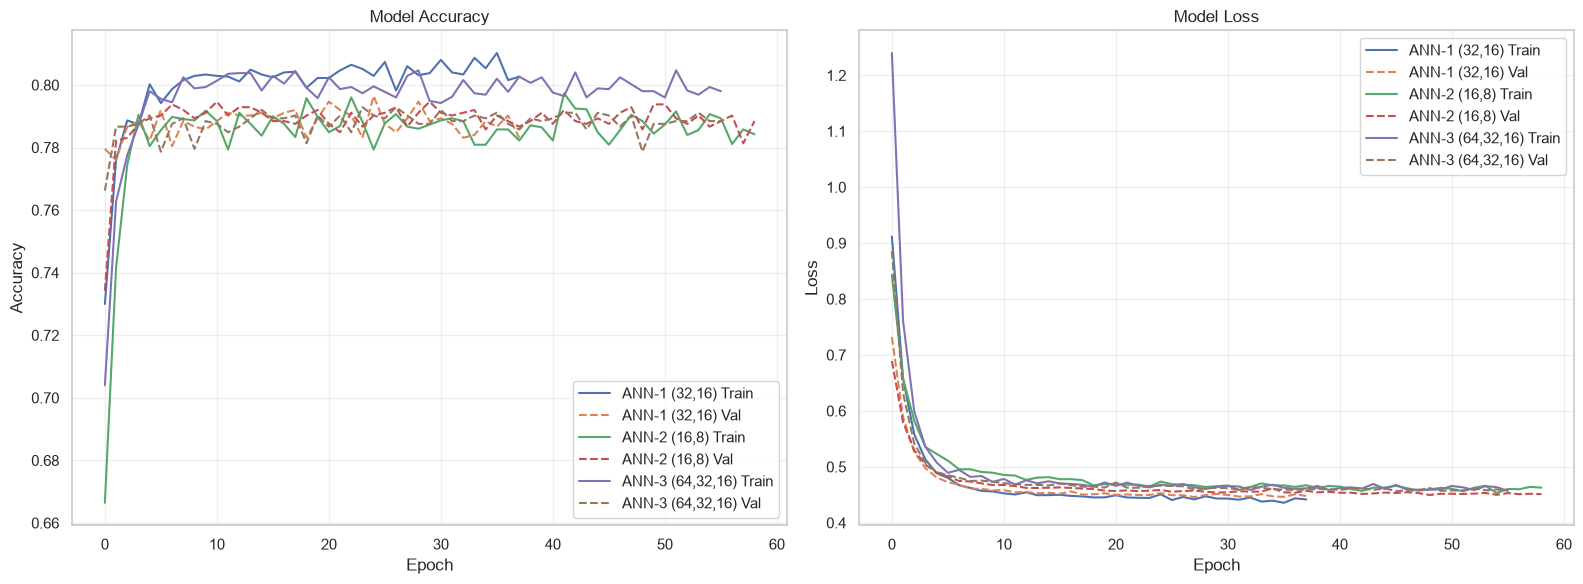

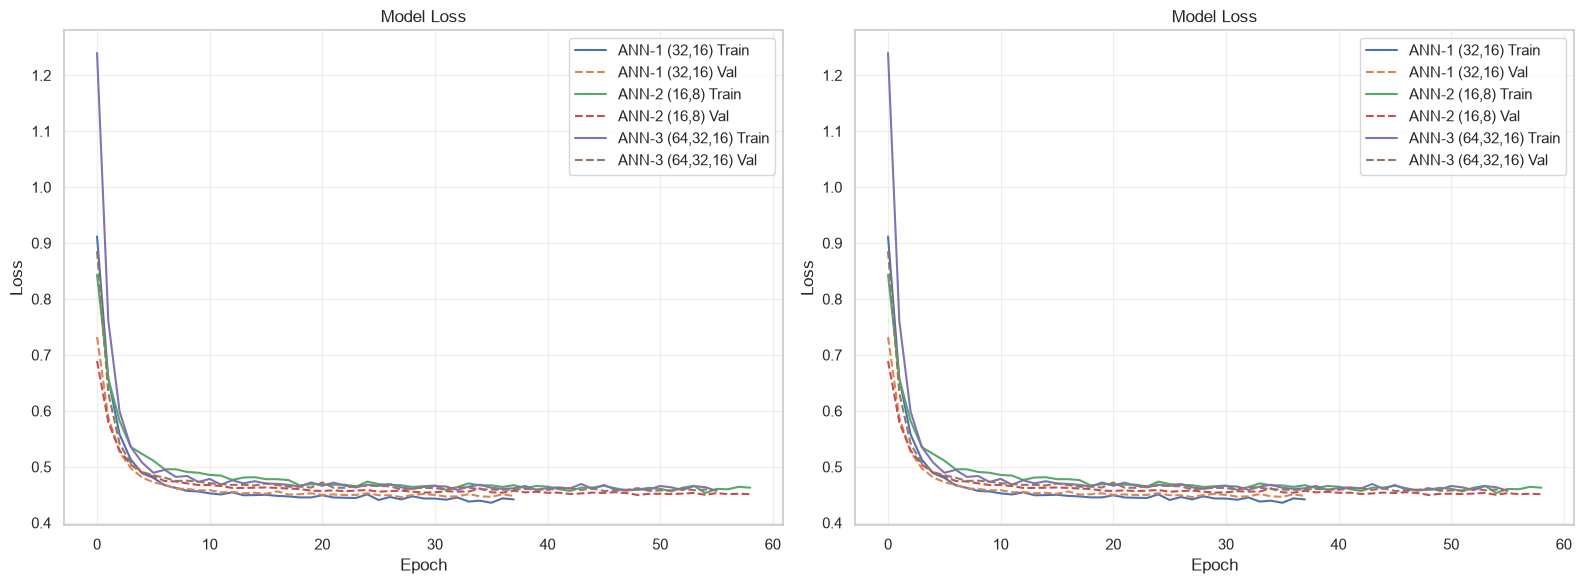

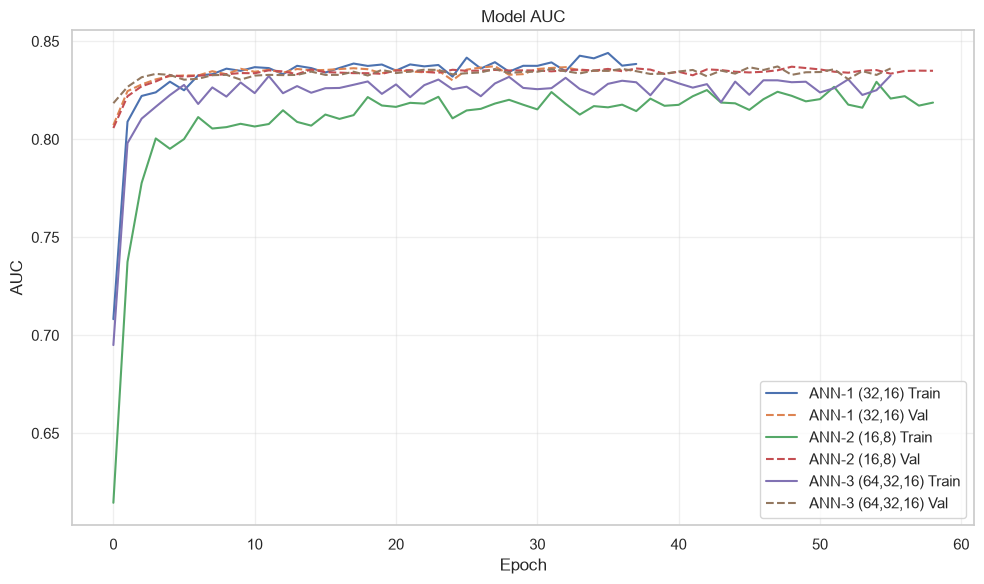

In [35]:
def plot_training_history(histories, labels, metric='accuracy'):
    """Plot training/validation curves for multiple models."""
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    
    # Accuracy
    for h, label in zip(histories, labels):
        axes[0].plot(h.history[metric], label=f'{label} Train', linestyle='-')
        axes[0].plot(h.history[f'val_{metric}'], label=f'{label} Val', linestyle='--')
    axes[0].set_title(f'Model {metric.capitalize()}')
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel(metric.capitalize())
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)
    
    # Loss
    for h, label in zip(histories, labels):
        axes[1].plot(h.history['loss'], label=f'{label} Train', linestyle='-')
        axes[1].plot(h.history['val_loss'], label=f'{label} Val', linestyle='--')
    axes[1].set_title('Model Loss')
    axes[1].set_xlabel('Epoch')
    axes[1].set_ylabel('Loss')
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()

histories = [history_ann1, history_ann2, history_ann3]
labels = ['ANN-1 (32,16)', 'ANN-2 (16,8)', 'ANN-3 (64,32,16)']

plot_training_history(histories, labels, 'accuracy')
plot_training_history(histories, labels, 'loss')

# Also plot AUC
fig, ax = plt.subplots(figsize=(10, 6))
for h, label in zip(histories, labels):
    ax.plot(h.history['auc'], label=f'{label} Train', linestyle='-')
    ax.plot(h.history['val_auc'], label=f'{label} Val', linestyle='--')
ax.set_title('Model AUC')
ax.set_xlabel('Epoch')
ax.set_ylabel('AUC')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 17. All Models Comparison


Complete Model Comparison:


,Accuracy,Precision,Recall,F1,ROC-AUC
Logistic Regression,0.80,0.64,0.57,0.60,0.84
Random Forest,0.75,0.52,0.80,0.63,0.84
XGBoost,0.74,0.51,0.81,0.62,0.84
"ANN-1 (32,16)",0.80,0.66,0.54,0.59,0.84
"ANN-2 (16,8)",0.80,0.64,0.58,0.61,0.84
"ANN-3 (64,32,16)",0.80,0.66,0.53,0.59,0.84


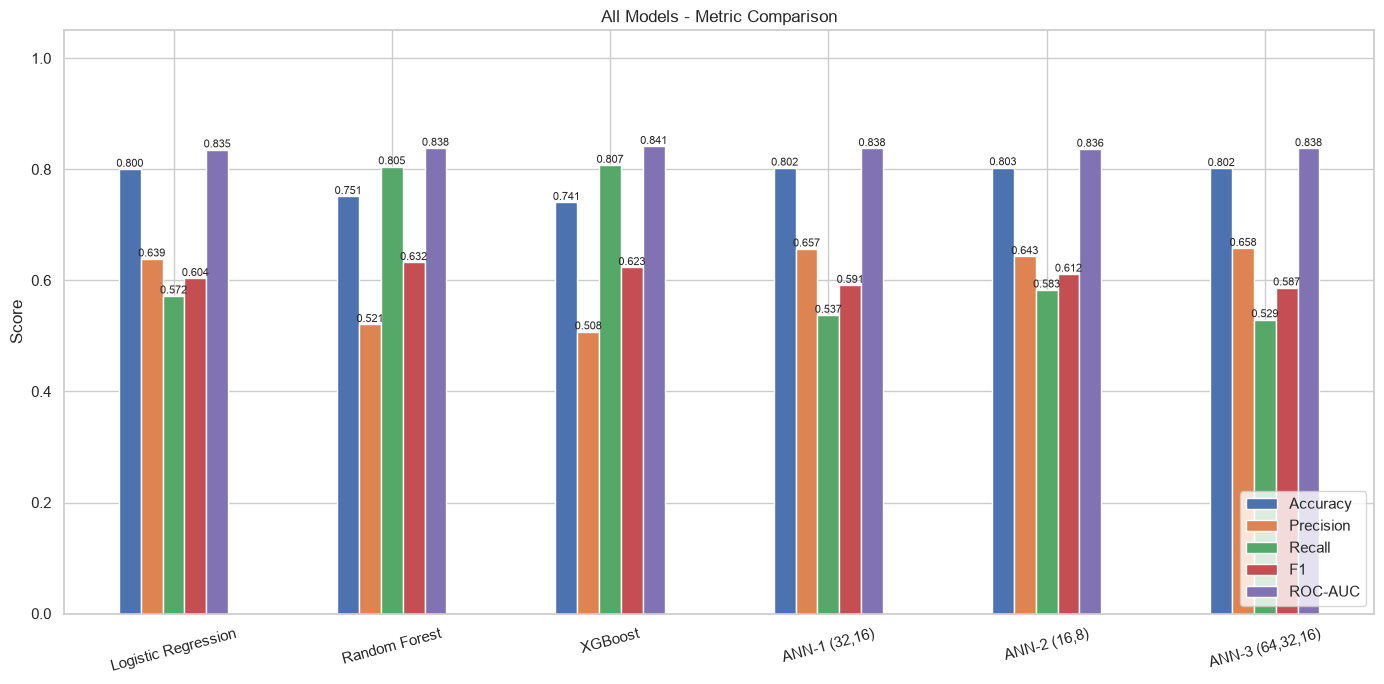

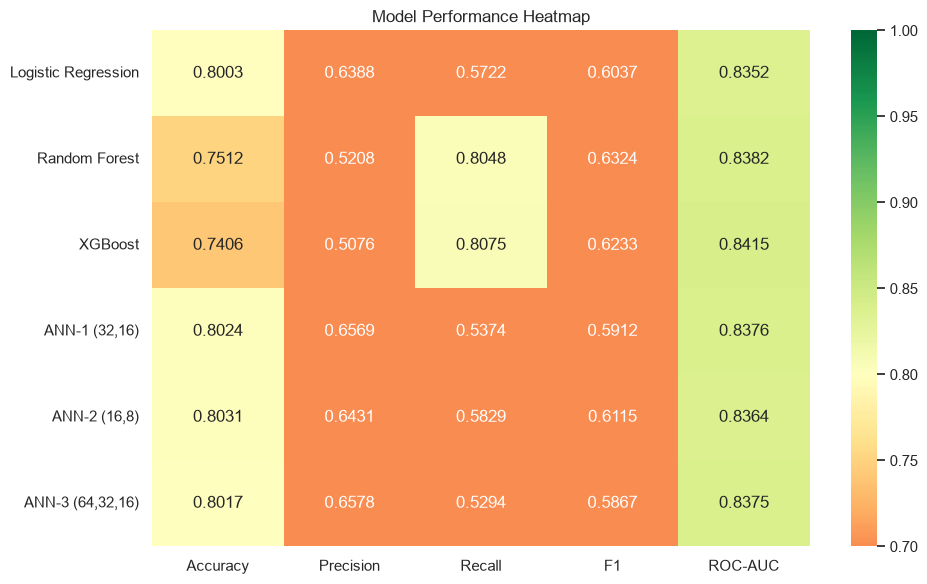

In [36]:
# Combine all results
all_results = pd.DataFrame({
    'Logistic Regression': lr_metrics,
    'Random Forest': rf_metrics,
    'XGBoost': xgb_metrics,
    'ANN-1 (32,16)': ann1_metrics,
    'ANN-2 (16,8)': ann2_metrics,
    'ANN-3 (64,32,16)': ann3_metrics
}).T

print('\nComplete Model Comparison:')
display(all_results.round(4))

# Bar plot - all models
fig, ax = plt.subplots(figsize=(14, 7))
all_results[['Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC']].plot(kind='bar', ax=ax)
ax.set_title('All Models - Metric Comparison')
ax.set_ylabel('Score')
ax.set_ylim(0, 1.05)
ax.legend(loc='lower right')
ax.tick_params(axis='x', rotation=15)
for container in ax.containers:
    ax.bar_label(container, fmt='%.3f', fontsize=8)
plt.tight_layout()
plt.show()

# Heatmap
fig, ax = plt.subplots(figsize=(10, 6))
sns.heatmap(all_results[['Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC']].round(4), 
            annot=True, fmt='.4f', cmap='RdYlGn', center=0.8, 
            vmin=0.7, vmax=1.0, ax=ax)
ax.set_title('Model Performance Heatmap')
plt.tight_layout()
plt.show()

## 18. Summary & Conclusions

### Best Performing Models
The comparison table and visualizations above show the relative performance of all six models.

### Key Observations
1. **Tree-based ensembles (Random Forest, XGBoost)** typically excel on tabular data with mixed feature types
2. **Logistic Regression** provides a strong baseline with interpretable coefficients
3. **ANN architectures** show how hidden layer capacity affects performance:
   - ANN-1 (32,16): Balanced capacity
   - ANN-2 (16,8): May underfit if too small
   - ANN-3 (64,32,16): Higher capacity, may overfit without enough data/regularization

### Recommendations for Production
1. **Select the model** with the best ROC-AUC and F1 balance based on business costs of false positives vs false negatives
2. **Calibrate probabilities** if needed (Platt scaling / isotonic regression)
3. **Monitor data drift** in production
4. **Consider ensemble** of top models for robust predictions

### Next Steps (if continuing)
- Gradient Boosting (LightGBM, CatBoost)
- KNN and SVM as originally planned
- SHAP values for model interpretability
- A/B testing framework for deployment